# AcademicVault: batching, timing and learning for certificate anchoring

Pipeline: fee data → window classifier or trigger rule → pending queue with SLA guard → Merkle batch → anchor → verification.

**Policies, all run on identical workloads:** P0 immediate · P1 fixed interval · P2 threshold · P2b fee-dependent queue · P3–P6 window policies (random, hour prior, ML, oracle label) · P7 tabular Q-learning · P8 clairvoyant reference (not deployable) · P2p / P9 / P10p / P10 / P10o slack-aware family (section 7i).

**Protocol:** expanding-window walk-forward folds with an embargo. Every setting is chosen on a validation block before the fold and scored once on the fold. Bootstrap CIs are paired by fold, and scheduler invariants are checked on every run. If no CSVs are found the notebook falls back to synthetic fee data, which is only a smoke test (set `ALLOW_SYNTHETIC_FALLBACK = False` to forbid it).

**Version history (tagged `[vN]` in the cells):** v7 fold modes, P8, stress test, paired CIs · v8 RL fixes · v9 matched-budget comparison, multi-seed RL, results pack · v10 SLA sensitivity · v11 slack-aware timing (7i), monthly folds by default.

**New in v12 version:** sections 5 to 7i give the same results as v11. Added:
1. **7i-5**: seed-to-seed variance of the P10 forecaster (new cell after 7i-1).
2. **7i-6**: fold-level cost-versus-wait curves, one line per fold (new cell after 7i-4).
3. Larger fonts and figure sizes for the paper figures.

## What this notebook claims, and what it doesn't
Each claim below is backed by a table or figure the notebook produces.
1. **Setting:** academic certificates with a hard 24 h SLA, anchored through Merkle batching, Ed25519 signatures and independent verification, tested end to end.
2. **Protocol:** walk-forward evaluation with an embargo, validation-only model and setting selection, and invariants asserted on every simulated run.
3. **Headroom:** P8 and the oracle-label window policy P6 show how much any timing policy could gain. The answer is "not much", which is a result in itself (see 7b-2).
4. **RL against tuned rules** at matched wait budgets, with multi-seed spread, under Poisson and bursty arrivals.
5. **Negative results, reported as they are:** ML window prediction versus the hour-of-day prior.
6. **Slack-aware timing (7i):** a deadline-aware percentile ramp (P9) and an ML forecast of the value of waiting (P10), compared at equal wait with tuned static rules, an hour-prior version of the same trigger, tabular RL and an oracle of the same family.

Section 12 labels every claim SUPPORTED, MIXED or NOT SUPPORTED.

**Closest prior work:** Mamageishvili & Felten on rollup batch posting (arXiv 2212.10337) and Bar-On & Mansour on optimal publishing (arXiv 2312.06448).

## 1. Imports and configuration

In [ ]:
# %pip install -q scikit-learn pandas numpy matplotlib cryptography xgboost
import json, glob, base64, hashlib, random, copy, time, shutil, sys, platform
from pathlib import Path
from datetime import datetime, timezone
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from cryptography.hazmat.primitives.asymmetric.ed25519 import Ed25519PrivateKey
try:
    from xgboost import XGBClassifier; HAVE_XGB = True
except ImportError:
    from sklearn.ensemble import HistGradientBoostingClassifier; HAVE_XGB = False

SEED = 42; random.seed(SEED); np.random.seed(SEED); NB_T0 = time.time()
ART = Path("artifacts"); ART.mkdir(exist_ok=True)
# [v7] white figure background so plots stay readable in dark-mode notebooks
plt.rcParams.update({"figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
                     "text.color": "#111111", "axes.labelcolor": "#111111", "xtick.color": "#111111", "ytick.color": "#111111",
                     "axes.edgecolor": "#444444"})

# ---------------- configuration ----------------
STEP_MIN = 5
SLA_HOURS, N_WINDOWS = 24, 4
WIN_STEPS = SLA_HOURS * 60 // STEP_MIN // N_WINDOWS     # 72 steps = 6 h
SLA_STEPS = WIN_STEPS * N_WINDOWS                        # 288 steps = 24 h
GUARD_STEPS = 6                                          # guard fires 30 min before the deadline
PCTL = 0.20; THR_LOOKBACK = 288                          # trigger: fee <= rolling 20th percentile (24 h)
LABEL_Q = PCTL                                           # window label = lowest 20th-percentile fee
FIXED_INTERVAL_STEPS = 144                               # 12 h baseline
# walk-forward folds: (test start, test end); each fold trains on everything before it
# [v7] FOLD_MODE: "quarterly" = 6 folds (Draft v4 setting); "monthly" = 20 rolling folds (more power for the classifier/CI tests)
FOLD_MODE = "monthly"      # [v11] default: 20 monthly folds for statistical power; set "quarterly" to reproduce the 6-fold v10 results
if FOLD_MODE == "monthly":
    _m = pd.date_range("2025-01-01", "2026-09-01", freq="MS")
    FOLDS = [(a.strftime("%Y-%m-%d"), b.strftime("%Y-%m-%d")) for a, b in zip(_m[:-1], _m[1:])]
else:
    FOLDS = [("2025-01-01","2025-04-01"), ("2025-04-01","2025-07-01"), ("2025-07-01","2025-10-01"),
             ("2025-10-01","2026-01-01"), ("2026-01-01","2026-04-01"), ("2026-04-01","2026-09-01")]
RL_ALL_CELLS = (FOLD_MODE == "quarterly")   # monthly mode trains RL only for the main cell and the bursty-workload cell (runtime)
VAL_DAYS = 60                                            # last 60 days before a fold = validation for model selection
BOOT_B = 2000
# simulation sweep
RATES = [0.05, 0.2, 1.0]; CAPS = [50, 200, 1000]; MAIN_RATE, MAIN_CAP = 1.0, 50
SEEDS_SWEEP = [17, 41, 89]
# RL (tabular Q-learning) settings
RL_MAX_EP, RL_EP_STEPS, RL_CKPTS = 600, 600, (100, 300, 600)   # episodes, steps per episode (~2 days), checkpoints compared on validation
RL_ALPHA0, RL_GAMMA, RL_DELAY, RL_CLIP = 0.2, 0.995, 0.005, 5.0   # RL_DELAY = holding cost per waiting certificate per step
# [v8] gamma 0.97 -> 0.995 (v7's 0.97 per 5-min step discounts the later anchor cost away and favours WAIT); delay 0.0005 -> 0.005
# [v9] matched-budget comparison of tuned rules vs RL (all settings chosen on the validation block), see section 7f
RL_N_SEEDS = 5                                              # independent RL trainings per delay setting (set 3 to roughly halve the RL runtime)
RL_DELAY_GRID = [0.0005, 0.002, 0.005, 0.02, 0.05]          # holding-cost weights tried for RL
RULE_INTERVALS = [12, 24, 36, 48, 60, 72, 144]              # fixed-interval P1 candidates (5-min steps: 1 h ... 12 h)
RULE_MINB = [1, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50]      # min_batch candidates for P2 and P2b
WAIT_BUDGETS = {"poisson": [80, 100, 120], "bursty": [150, 200, 250], "real": [100, 150, 200]}   # average-wait budgets (minutes) per workload
SLA_SENS_HOURS = [6, 12, 24, 48]    # [v10] deadlines tried in section 7h (24 h is the primary setting; the main sections always use SLA_HOURS)
SLA_SENS_RL = True                  # [v10] train one RL agent per fold and SLA in 7h (adds roughly 1-2 min per SLA); set False to skip RL there
RL_EXPLORING_STARTS = True    # [v8] episodes start with a random backlog of random age (set False to reproduce v7 behaviour)
# PLACEHOLDER gas model: replace with values measured on Sepolia/Amoy
INDIVIDUAL_GAS, BATCH_BASE_GAS, PER_CRED_GAS, PRIORITY_GWEI = 90_000, 100_000, 0, 0.0
# [v7] optional measured gas: put measured_gas.csv next to the notebook (columns: kind = single|batch, batch_size, gas_used).
GAS_CSV, GAS_SOURCE = "measured_gas.csv", "PLACEHOLDER (not measured)"
if Path(GAS_CSV).exists():
    _g = pd.read_csv(GAS_CSV); _g.columns = [c.strip().lower() for c in _g.columns]
    _s, _b = _g[_g.kind.str.lower() == "single"], _g[_g.kind.str.lower() == "batch"]
    if len(_s): INDIVIDUAL_GAS = int(round(_s.gas_used.mean()))
    if _b.batch_size.nunique() >= 2:
        _slope, _icpt = np.polyfit(_b.batch_size.astype(float), _b.gas_used.astype(float), 1)
        PER_CRED_GAS, BATCH_BASE_GAS = max(0, int(round(_slope))), int(round(_icpt))
    elif len(_b): BATCH_BASE_GAS = int(round(_b.gas_used.mean()))
    GAS_SOURCE = f"measured ({GAS_CSV})"
CSV_FILES = ["ethereum_fee_5min_2024.csv", "ethereum_fee_5min_2025.csv", "ethereum_fee_5min_2026_jan_aug.csv"]
ALLOW_SYNTHETIC_FALLBACK = True
DATA_SOURCE_NOTE = "TODO: name the fee-data provider / query used to obtain the CSVs"   # [v7] saved to artifacts/data_provenance.json
ISSUANCE_CSV = "issuance_times.csv"      # [v7] optional real issuance trace: one column `timestamp` (UTC), see §7g
CLAIR_LOOK = WIN_STEPS                   # [v7] look-ahead (steps) of the clairvoyant reference policy P8
def min_batch_for(rate, cap):   # low-fee trigger needs this many pending (half the expected arrivals in one window)
    return int(max(1, min(cap // 2, round(rate * WIN_STEPS / 2))))
print("Window =", WIN_STEPS, "steps | XGBoost:", HAVE_XGB, "| folds:", FOLD_MODE, len(FOLDS), "| gas model:", GAS_SOURCE,
      f"(single={INDIVIDUAL_GAS:,}, batch={BATCH_BASE_GAS:,} + {PER_CRED_GAS:,}/cert)")

# [v11] slack-aware timing (section 7i): P9 = slack-ramped percentile threshold (no ML), P10 = ML wait-value trigger, P2p / P10p / P10o = controls
PGRID = np.round(np.arange(0.05, 0.951, 0.05), 2)                       # rolling-percentile levels available to the ramp rule (19 levels)
HZ = (12, 36, 72, 144, 288)                                             # look-ahead horizons in 5-min steps = 1, 3, 6, 12, 24 h; the remaining slack picks the horizon
RAMP_PLO, RAMP_PHI, RAMP_K = [0.10, 0.20, 0.30], [0.50, 0.80], [1, 3]   # P9 candidate grid: starting percentile, final percentile, ramp shape
WV_MARGINS = [0.0, 0.25, 0.50, 1.0, 2.0, 3.0, 6.0]                      # P10 margin m (log-fee units): anchor when the predicted saving from waiting <= m (6.0 = almost always)
V11_MINB = [1, 10, 20, 30, 40, 50]                                      # min_batch values tried by P2p / P9 / P10
WV_TRAIN_STRIDE = 6                                                     # wait-value models train on every 6th 5-min step (30 min)
V11_BUDGET_GRID = {"poisson": [70, 80, 90, 100, 110, 120, 130], "bursty": [110, 125, 150, 175, 200, 225, 250], "real": [80, 100, 125, 150, 175, 200]}   # wait budgets (min) that trace each family's cost-vs-wait curve (equal-wait comparison)
plt.rcParams.update({"font.size": 12, "axes.titlesize": 12, "axes.labelsize": 12, "xtick.labelsize": 11, "ytick.labelsize": 11, "legend.fontsize": 10})   # larger text for paper figures


Window = 72 steps | XGBoost: True | folds: monthly 20 | gas model: PLACEHOLDER (not measured) (single=90,000, batch=100,000 + 0/cert)


#### [v7] Measuring gas (replaces the placeholder gas model)
Measure gas units (not fees) on a testnet such as Sepolia or Amoy, e.g. with Hardhat or Foundry gas reports, and save `measured_gas.csv` next to this notebook:

```
kind,batch_size,gas_used
single,1,<gas of your single-hash store call>
batch,1,<gas of the root-anchor call with 1 leaf>
batch,10,...
batch,50,...
batch,200,...
batch,1000,...
```
The notebook fits `gas = base + per_cert × batch_size` and applies it to the real mainnet fee series. Until the file exists, results are labelled `PLACEHOLDER` in the config printout.

## 2. Fee data: load

In [ ]:
REQUIRED = ["interval_start", "avg_base_fee_gwei", "avg_gas_utilization", "blocks_in_interval"]

def make_synthetic():
    """Smoke-test data only. NOT real Ethereum fees."""
    idx = pd.date_range("2024-01-01", "2026-08-31 23:55", freq="5min", tz="UTC")
    n = len(idx); rng = np.random.default_rng(0)
    hour = idx.hour.values + idx.minute.values / 60
    base = 0.04 * (1 + 0.25 * np.sin(2 * np.pi * (hour - 14) / 24))
    noise = np.zeros(n); e = rng.normal(0, 0.15, n)
    for i in range(1, n):
        noise[i] = 0.995 * noise[i - 1] + e[i]
    fee = base * np.exp(noise)
    spikes = rng.random(n) < 0.001
    fee[spikes] *= rng.uniform(3, 20, spikes.sum())
    return pd.DataFrame({
        "interval_start": idx, "avg_base_fee_gwei": fee,
        "avg_gas_utilization": np.clip(0.5 + 0.1 * rng.normal(size=n), 0, 1),
        "blocks_in_interval": rng.integers(20, 26, n).astype(float),
    })

found = [f for f in CSV_FILES if Path(f).exists()] or sorted(f for f in glob.glob("*.csv") if f not in (ISSUANCE_CSV, GAS_CSV))   # [v9] side files are not fee data
USING_SYNTHETIC = False
if found:
    raw = pd.concat([pd.read_csv(f).rename(columns=lambda c: str(c).strip().lower()) for f in found], ignore_index=True)
    print("Loaded:", found)
elif ALLOW_SYNTHETIC_FALLBACK:
    raw = make_synthetic(); USING_SYNTHETIC = True
    print("#" * 70, "\n# SYNTHETIC DATA: smoke test only. Results are NOT research results. #\n" + "#" * 70)
else:
    raise FileNotFoundError("Upload the Ethereum 5-minute fee CSV files.")
missing = set(REQUIRED) - set(raw.columns)
assert not missing, f"CSV missing columns: {missing}"
print("Raw shape:", raw.shape)
# [v7] data provenance: row counts + SHA-256 of every CSV used 
if not USING_SYNTHETIC:
    prov = {"data_source_note": DATA_SOURCE_NOTE,
            "files": [{"file": f, "rows": sum(1 for _ in open(f, "rb")) - 1, "sha256": hashlib.sha256(Path(f).read_bytes()).hexdigest()} for f in found]}
    with open(ART / "data_provenance.json", "w") as fh: json.dump(prov, fh, indent=2)
    print(json.dumps(prov, indent=2))

Loaded: ['ethereum_fee_5min_2024.csv', 'ethereum_fee_5min_2025.csv', 'ethereum_fee_5min_2026_jan_aug.csv']
Raw shape: (280512, 4)
{
  "data_source_note": "TODO: name the fee-data provider / query used to obtain the CSVs",
  "files": [
    {
      "file": "ethereum_fee_5min_2024.csv",
      "rows": 105408,
      "sha256": "fe58ec805102db10c47201802fbb0723909a65b07a5ca686e072682f7b547d96"
    },
    {
      "file": "ethereum_fee_5min_2025.csv",
      "rows": 105120,
      "sha256": "0254697a87d511735276a318702761fedb3f37719f21de725d706fc48d02d5d8"
    },
    {
      "file": "ethereum_fee_5min_2026_jan_aug.csv",
      "rows": 69984,
      "sha256": "cda69f44538b81bca90c92c803b9e43057c3eb55dc12c7595739a49ca82d4c97"
    }
  ]
}


## 3. Clean and validate

In [3]:
df = raw[REQUIRED].copy()
df["interval_start"] = pd.to_datetime(df["interval_start"], utc=True, errors="coerce")
for c in REQUIRED[1:]:
    df[c] = pd.to_numeric(df[c], errors="coerce")
df = (df.dropna(subset=["interval_start"]).sort_values("interval_start")
        .drop_duplicates("interval_start", keep="last").set_index("interval_start").asfreq("5min"))
n_inserted = int(df["avg_base_fee_gwei"].isna().sum())
df["avg_base_fee_gwei"] = df["avg_base_fee_gwei"].ffill()
df["avg_gas_utilization"] = df["avg_gas_utilization"].ffill()
df["blocks_in_interval"] = df["blocks_in_interval"].fillna(0)
df = df.dropna().reset_index()
assert (df["avg_base_fee_gwei"] >= 0).all(), "negative fees in data"
fee = df["avg_base_fee_gwei"].values.astype(float)
N = len(df)
print(f"Rows: {N:,} | {df.interval_start.min()} -> {df.interval_start.max()} | filled gaps: {n_inserted}")
print(f"Fee gwei: mean={fee.mean():.4f} median={np.median(fee):.4f} p95={np.percentile(fee,95):.4f} max={fee.max():.2f}")

Rows: 280,512 | 2024-01-01 00:00:00+00:00 -> 2026-08-31 23:55:00+00:00 | filled gaps: 0
Fee gwei: mean=6.9045 median=0.9700 p95=32.5015 max=654.85


## 4. Features and window labels
Features at time *t* use data up to *t* only and are scale-free. The label is the one of four 6-hour windows after *t* with the lowest 20th-percentile fee.

In [4]:
EPS = 1e-6
FEATURE_COLS = ["lr_now_24h","lr_1h_24h","lr_6h_24h","cv_24h","lr_lagday_24h","lr_lagweek_24h",
                "util_mean_1h","blocks_mean_1h","hour_sin","hour_cos","dow_sin","dow_cos"]

def build_features(d):
    """Causal and scale-free: row t uses only rows <= t; no raw gwei levels."""
    f = d["avg_base_fee_gwei"]; u = d["avg_gas_utilization"]; b = d["blocks_in_interval"]
    m1, m6, m24, s24 = f.rolling(12).mean(), f.rolling(72).mean(), f.rolling(288).mean(), f.rolling(288).std()
    lag_d, lag_w = f.shift(288).rolling(12).mean(), f.shift(2016).rolling(12).mean()
    lr = lambda a, c: np.log((a + EPS) / (c + EPS))
    X = pd.DataFrame(index=d.index)
    X["lr_now_24h"] = lr(f, m24); X["lr_1h_24h"] = lr(m1, m24); X["lr_6h_24h"] = lr(m6, m24)
    X["cv_24h"] = s24 / (m24 + EPS)
    X["lr_lagday_24h"] = lr(lag_d, m24); X["lr_lagweek_24h"] = lr(lag_w, m24)
    X["util_mean_1h"] = u.rolling(12).mean(); X["blocks_mean_1h"] = b.rolling(12).mean()
    hr = d["interval_start"].dt.hour + d["interval_start"].dt.minute / 60; dw = d["interval_start"].dt.dayofweek
    X["hour_sin"], X["hour_cos"] = np.sin(2*np.pi*hr/24), np.cos(2*np.pi*hr/24)
    X["dow_sin"], X["dow_cos"] = np.sin(2*np.pi*dw/7), np.cos(2*np.pi*dw/7)
    return X[FEATURE_COLS]

def window_stat(f_series, q=None):
    """S[t,k] = statistic (mean if q is None else q-quantile) of fees over steps (t+k*72, t+(k+1)*72]; NaN if future incomplete."""
    r = f_series.rolling(WIN_STEPS); m = r.mean() if q is None else r.quantile(q)
    return np.column_stack([m.shift(-(WIN_STEPS * (k + 1))).values for k in range(N_WINDOWS)])

fser = df["avg_base_fee_gwei"]
X_all = build_features(df).values.astype(float)
W_all = window_stat(fser, LABEL_Q)        # label statistic (used for labels and regret)
W_mean = window_stat(fser)                # secondary: plain mean
feat_ok = np.isfinite(X_all).all(1); lab_ok = np.isfinite(W_all).all(1) & np.isfinite(W_mean).all(1)
label_all = np.full(N, -1); label_all[lab_ok] = W_all[lab_ok].argmin(1)
ts = df["interval_start"]; idx_all = np.arange(N)
base_rows = feat_ok & lab_ok & (idx_all % 12 == 0)                   # hourly start times
print("Usable hourly rows:", int(base_rows.sum()), "| label share:", np.round(np.bincount(label_all[base_rows], minlength=4) / base_rows.sum(), 3))

Usable hourly rows: 23183 | label share: [0.236 0.228 0.236 0.3  ]


## 5. Window classifier, walk-forward
For each fold, train on rows that end at least 2×24 h + 60 days before the fold (the embargo), pick logistic regression or boosted trees on the 60-day validation block, then predict the fold. Baselines: random, yesterday's label, and an hour-of-day prior fitted on the same training rows.

In [5]:
emb, vd = pd.Timedelta(hours=SLA_HOURS), pd.Timedelta(days=VAL_DAYS)
hour_all = df["interval_start"].dt.hour.values
lab_yesterday = np.concatenate([np.full(SLA_STEPS, -1), label_all[:-SLA_STEPS]])
GB_NAME = "xgboost" if HAVE_XGB else "hist_gb"

def make_models(Xtr, ytr):
    lr_ = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)).fit(Xtr, ytr)
    if HAVE_XGB:
        gb_ = XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                            objective="multi:softprob", eval_metric="mlogloss", random_state=SEED, n_jobs=-1).fit(Xtr, ytr)
    else:
        gb_ = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200, random_state=SEED).fit(Xtr, ytr)
    return {"logreg": lr_, GB_NAME: gb_}

def regret(W, pred): return W[np.arange(len(pred)), pred] - W.min(1)

fold_data = []
for fs, fe in FOLDS:
    fs_t, fe_t = pd.Timestamp(fs, tz="UTC"), pd.Timestamp(fe, tz="UTC")
    tr = np.where(base_rows & (ts < fs_t - vd - 2 * emb))[0]
    va = np.where(base_rows & (ts >= fs_t - vd - emb) & (ts < fs_t - emb))[0]
    te = np.where(base_rows & (ts >= fs_t) & (ts < fe_t))[0]
    if min(len(tr), len(va), len(te)) < 200 or len(set(label_all[tr])) < N_WINDOWS:
        print(f"skip fold {fs}: rows train/val/test = {len(tr)}/{len(va)}/{len(te)}"); continue
    models = make_models(X_all[tr], label_all[tr])
    hp = pd.Series(label_all[tr]).groupby(hour_all[tr]).agg(lambda s: s.value_counts().idxmax())
    pred_hour = lambda rows, hp=hp: pd.Series(hour_all[rows]).map(hp).fillna(0).astype(int).values
    val_reg = {n: float(regret(W_all[va], m.predict(X_all[va])).mean()) for n, m in models.items()}
    sel = min(val_reg, key=val_reg.get)
    preds = {"yesterday": np.where(lab_yesterday[te] >= 0, lab_yesterday[te], 0), "hour prior": pred_hour(te)}
    probas = {}
    for n, m in models.items():
        probas[n] = m.predict_proba(X_all[te]); preds[n] = probas[n].argmax(1)
    preds["selected"], probas["selected"] = preds[sel], probas[sel]
    lo = int(np.searchsorted(ts.values, np.datetime64(fs_t.tz_convert(None)))); hi = min(N, int(np.searchsorted(ts.values, np.datetime64(fe_t.tz_convert(None)))))
    fold_data.append(dict(fs=fs, fe=fe, lo=lo, hi=hi, te=te, models=models, sel=sel, hp=hp, pred_hour=pred_hour, preds=preds, probas=probas))
    print(f"fold {fs}: train {len(tr):,} val {len(va):,} test {len(te):,} | selected on validation: {sel}")
assert fold_data, "no usable folds: check data coverage"

# ---- pooled results with day-block bootstrap ----
rows_all = np.concatenate([f["te"] for f in fold_data]); W_te = W_all[rows_all]; y_te = label_all[rows_all]
R_rand = W_te.mean(1) - W_te.min(1)
METHODS = ["yesterday", "hour prior"] + list(fold_data[0]["models"]) + ["selected"]
P = {m: np.concatenate([f["preds"][m] for f in fold_data]) for m in METHODS}
PR = {m: np.concatenate([f["probas"][m] for f in fold_data]) for m in METHODS if m in fold_data[0]["probas"]}
R = {m: regret(W_te, P[m]) for m in METHODS}
day = pd.factorize(ts.dt.floor("D").values[rows_all])[0]; D = day.max() + 1
BOOT = np.random.default_rng(SEED).integers(0, D, (BOOT_B, D))
def boot_ratio(Rm):
    sm = np.bincount(day, weights=Rm, minlength=D); sr = np.bincount(day, weights=R_rand, minlength=D)
    return 100 * sm[BOOT].sum(1) / sr[BOOT].sum(1)
b_hour = boot_ratio(R["hour prior"])
tbl = [{"method": "random (expected)", "accuracy": 0.25, "top2_acc": 0.5, "regret_pct_of_random": 100.0, "95% CI": "-", "diff vs hour prior (pts)": "-"}]
for m in METHODS:
    b = boot_ratio(R[m]); d_ = b - b_hour
    top2 = float((np.argsort(PR[m], 1)[:, -2:] == y_te[:, None]).any(1).mean()) if m in PR else np.nan
    tbl.append({"method": m, "accuracy": float((P[m] == y_te).mean()), "top2_acc": top2,
                "regret_pct_of_random": 100 * R[m].sum() / R_rand.sum(),
                "95% CI": f"[{np.percentile(b, 2.5):.1f}, {np.percentile(b, 97.5):.1f}]",
                "diff vs hour prior (pts)": "-" if m == "hour prior" else f"{d_.mean():+.2f} [{np.percentile(d_, 2.5):+.2f}, {np.percentile(d_, 97.5):+.2f}]"})
tbl.append({"method": "oracle", "accuracy": 1.0, "top2_acc": 1.0, "regret_pct_of_random": 0.0, "95% CI": "-", "diff vs hour prior (pts)": "-"})
win_tbl = pd.DataFrame(tbl).set_index("method")
print("POOLED walk-forward (all folds). regret_pct_of_random: 100 = random, 0 = perfect. Negative 'diff' = better than hour prior.")
display(win_tbl.round(3)); win_tbl.to_csv(ART / "window_walkforward.csv")

fold_rows = []
for f in fold_data:
    W = W_all[f["te"]]; rr = (W.mean(1) - W.min(1)).sum()
    fold_rows.append({"fold": f["fs"], "selected": f["sel"], **{m: 100 * regret(W, f["preds"][m]).sum() / rr for m in ["hour prior", "selected"]}})
fold_tbl = pd.DataFrame(fold_rows).set_index("fold")
fold_tbl["ML beats hour prior"] = fold_tbl["selected"] < fold_tbl["hour prior"]
print("Per-fold regret (% of random):"); display(fold_tbl.round(2)); fold_tbl.to_csv(ART / "window_per_fold.csv")
print(f"ML beats hour prior in {int(fold_tbl['ML beats hour prior'].sum())} of {len(fold_tbl)} folds")
mean_reg = {m: 100 * regret(W_mean[rows_all], P[m]).sum() / (W_mean[rows_all].mean(1) - W_mean[rows_all].min(1)).sum() for m in ["hour prior", "selected"]}
print("Secondary check on mean-fee windows (regret % of random):", {k: round(v, 1) for k, v in mean_reg.items()})

fold 2025-01-01: train 7,127 val 1,440 test 744 | selected on validation: xgboost
fold 2025-02-01: train 7,871 val 1,440 test 672 | selected on validation: xgboost
fold 2025-03-01: train 8,543 val 1,440 test 744 | selected on validation: xgboost
fold 2025-04-01: train 9,287 val 1,440 test 720 | selected on validation: xgboost
fold 2025-05-01: train 10,007 val 1,440 test 744 | selected on validation: logreg
fold 2025-06-01: train 10,751 val 1,440 test 720 | selected on validation: logreg
fold 2025-07-01: train 11,471 val 1,440 test 744 | selected on validation: logreg
fold 2025-08-01: train 12,215 val 1,440 test 744 | selected on validation: xgboost
fold 2025-09-01: train 12,959 val 1,440 test 720 | selected on validation: xgboost
fold 2025-10-01: train 13,679 val 1,440 test 744 | selected on validation: logreg
fold 2025-11-01: train 14,423 val 1,440 test 720 | selected on validation: logreg
fold 2025-12-01: train 15,143 val 1,440 test 744 | selected on validation: logreg
fold 2026-01-0

,accuracy,top2_acc,regret_pct_of_random,95% CI,diff vs hour prior (pts)
method,,,,,
random (expected),0.250,0.500,100.000,-,-
yesterday,0.467,NaN,51.472,"[35.6, 67.7]","+20.91 [+11.87, +30.20]"
hour prior,0.562,NaN,30.534,"[16.7, 44.6]",-
logreg,0.566,0.885,30.421,"[17.4, 44.2]","-0.02 [-3.59, +3.32]"
xgboost,0.572,0.888,28.700,"[16.9, 41.4]","-1.60 [-7.38, +3.80]"
selected,0.568,0.884,28.186,"[16.4, 40.9]","-2.11 [-7.79, +3.32]"
oracle,1.000,1.000,0.000,-,-


Per-fold regret (% of random):


,selected,hour prior,ML beats hour prior
fold,,,
2025-01-01,33.87,37.08,True
2025-02-01,81.56,102.50,True
2025-03-01,13.88,15.53,True
2025-04-01,12.66,11.57,False
2025-05-01,13.59,11.26,False
2025-06-01,12.89,15.07,True
2025-07-01,20.02,20.10,True
2025-08-01,13.80,11.82,False
2025-09-01,6.33,6.59,True


ML beats hour prior in 12 of 20 folds
Secondary check on mean-fee windows (regret % of random): {'hour prior': np.float64(38.6), 'selected': np.float64(34.7)}


## 6. Queue, anchor trigger and SLA guard
The oldest ≤ `cap` certificates are anchored as soon as any trigger fires: the SLA guard (30 min before the deadline), a full queue, or the policy's own trigger.
- `rl`: the Q-learning agent (6b)
- `fixed`: 12 h after the first pending certificate
- `threshold`: fee ≤ p20 and at least `min_batch` pending
- `qfee`: fee-dependent queue size (p20: `min_batch`; ≤ p50: cap/2; otherwise only cap or the guard)
- `clair`: reference that looks ahead; anchors when at least `min_batch` are pending and the fee is the lowest of the next `CLAIR_LOOK` steps. It shows the timing headroom and is not deployable.
- `window`: inside the classifier's window with fee ≤ p20 and at least `min_batch` pending, or when that window ends

In [6]:
thr  = fser.rolling(THR_LOOKBACK).quantile(PCTL).values     # causal rolling 20th percentile
thr2 = fser.rolling(THR_LOOKBACK).quantile(0.50).values     # rolling median (for qfee)

import bisect
N_STATES, N_ACTIONS = 36, 4
def rl_state(f_t, a_t, b_t, q, cap, mb, rem):
    fb = 0 if f_t <= a_t else (1 if f_t <= b_t else 2)            # fee vs rolling p20 / p50 (NaN -> 2)
    qb = 0 if q < mb else (1 if q < cap // 2 else 2)              # queue size bucket
    ub = 0 if rem > 144 else (1 if rem > 72 else (2 if rem > 24 else 3))   # time left to the oldest deadline
    return (fb * 3 + qb) * 4 + ub
def rl_sizes(cap): return [0, max(1, cap // 4), max(1, cap // 2), cap]      # action 0 = WAIT, else anchor that many

def run_scheduler(fee, thr, thr2, arr, mode, cap, min_batch, interval=None, plan=None, qtab=None, start=0, end=None, aux=None):
    end = len(fee) if end is None else end
    n = len(arr); head = tail = 0; batches = []; t0 = None; k = 0; last_anchor = start
    for t in range(start, end):
        while tail < n and arr[tail] <= t: tail += 1
        q = tail - head
        if q == 0: t0 = None; continue
        if t0 is None:
            t0 = t; last_anchor = t; k = int(plan[t]) if plan is not None else 0
        guard = (t - arr[head]) >= SLA_STEPS - GUARD_STEPS
        full = q >= cap
        low = fee[t] <= thr[t] and q >= min_batch
        bsize = cap
        if mode == "fixed":       hit = (t - last_anchor) >= interval
        elif mode == "threshold": hit = low
        elif mode == "clair":     # [v7] peeks at future fees: reference only
            hit = q >= min_batch and fee[t] <= fee[t:min(end, t + CLAIR_LOOK)].min()
        elif mode == "qfee":
            need = min_batch if fee[t] <= thr[t] else (max(min_batch, cap // 2) if fee[t] <= thr2[t] else cap)
            hit = q >= need
        elif mode == "ramp":      # [v11] P9 / P2p: the percentile threshold rises with the age of the oldest pending certificate (slack shrinks)
            u = min(1.0, (t - arr[head]) / SLA_STEPS)
            gi = int(round((aux["p_lo"] + (aux["p_hi"] - aux["p_lo"]) * u ** aux["k"] - PGRID[0]) / 0.05)); gi = 0 if gi < 0 else (len(PGRID) - 1 if gi >= len(PGRID) else gi)
            hit = q >= min_batch and fee[t] <= aux["grid"][gi, t]
        elif mode == "wv":        # [v11] P10: anchor when the predicted saving from waiting (until the SLA guard) is at most the margin m
            s_ = min(SLA_STEPS - GUARD_STEPS - (t - arr[head]), HZ[-1]); hz = min(bisect.bisect_left(HZ, max(s_, 1)), len(HZ) - 1)
            hit = q >= min_batch and aux["pred"][hz][t] >= -aux["m"]
        elif mode == "rl":
            a_ = int(np.argmax(qtab[rl_state(fee[t], thr[t], thr2[t], q, cap, min_batch, SLA_STEPS - (t - arr[head]))]))
            hit = a_ > 0; bsize = rl_sizes(cap)[a_]
        else:
            rel = t - t0
            hit = (k * WIN_STEPS <= rel < (k + 1) * WIN_STEPS and low) or rel >= (k + 1) * WIN_STEPS - 1
        if guard or full or hit:
            b = min(q, cap if (guard or full) else bsize); batches.append((t, head, head + b)); head += b; last_anchor = t
    return batches, n - head

def batch_cost_eth(n_certs, fee_gwei, per_cred_gas=None):
    pc = PER_CRED_GAS if per_cred_gas is None else per_cred_gas
    return (BATCH_BASE_GAS + pc * n_certs) * (fee_gwei + PRIORITY_GWEI) * 1e-9

def evaluate(batches, arr, fee, per_cred_gas=None):
    cost = sum(batch_cost_eth(b - a, fee[t], per_cred_gas) for t, a, b in batches)
    waits = np.concatenate([(t - arr[a:b]) for t, a, b in batches])
    return {"cost_eth": cost, "avg_wait_min": float(waits.mean() * STEP_MIN), "sla_pct": 100 * float((waits <= SLA_STEPS).mean()),
            "transactions": len(batches), "mean_batch": float(len(arr) / len(batches)), "_max_wait": int(waits.max())}

def evaluate_immediate(arr, fee):
    return {"cost_eth": float((INDIVIDUAL_GAS * (fee[arr] + PRIORITY_GWEI) * 1e-9).sum()), "avg_wait_min": 0.0, "sla_pct": 100.0,
            "transactions": len(arr), "mean_batch": 1.0, "_max_wait": 0}
print("Scheduler ready.")

Scheduler ready.


## 6b. RL agent (P7): tabular Q-learning
**State (36):** fee bucket (≤ p20, ≤ p50, above) × queue bucket (below min batch, below cap/2, below cap) × urgency bucket (time left for the oldest certificate).
**Actions:** WAIT, or anchor ¼, ½ or all of the cap. The SLA guard and full-queue override still apply.
**Reward:** −(fee ÷ reference fee, clipped at 5) per transaction, − `RL_DELAY` × certificates still waiting, per step.
**[v8] Training:** discount 0.995 and exploring starts (random backlog with random ages) so every queue and urgency state gets visited.
**No peeking:** one agent per (fold, arrival rate, cap), trained only on data before a 60-day validation block that sits before the fold. Three checkpoints (episodes 100, 300, 600) are compared on that block and the cheapest is run greedily on the fold. This matters because tabular Q-learning on noisy fee rewards can get worse with more training.

In [7]:
def train_rl(fi, f, rate, cap, mb, delay=None, rl_seed=0, gen=None):   # [v9] rl_seed = independent training run; gen = arrival generator gen(rng, lo, hi)
    dl = RL_DELAY if delay is None else delay        # [v7] holding-cost weight is now an argument (Pareto sweep, §7f)
    rng = np.random.default_rng(SEED + 1000 * fi + int(rate * 1000) + cap + 7919 * rl_seed)
    val_len = VAL_DAYS * 288
    val_lo, val_hi = f["lo"] - val_len - SLA_STEPS, f["lo"] - SLA_STEPS            # validation block (before the fold)
    lo_r, hi_r = THR_LOOKBACK + 10, val_lo - SLA_STEPS                              # training strictly before validation
    assert hi_r - RL_EP_STEPS > lo_r and hi_r + SLA_STEPS <= val_lo and val_hi <= f["lo"] - SLA_STEPS, "RL split problem"
    ref = float(np.median(fee[lo_r:hi_r])) + 1e-9
    Q = np.zeros((N_STATES, N_ACTIONS)); sizes = rl_sizes(cap); cands = {}
    for ep in range(1, RL_MAX_EP + 1):
        eps = max(0.02, 0.3 * (1 - ep / (0.8 * RL_MAX_EP))); alpha = max(0.02, RL_ALPHA0 * (1 - ep / RL_MAX_EP))
        start = int(rng.integers(lo_r, hi_r - RL_EP_STEPS)); end = start + RL_EP_STEPS
        arr = gen(rng, start, end) if gen is not None else np.repeat(np.arange(start, end), rng.poisson(rate, RL_EP_STEPS))
        if RL_EXPLORING_STARTS:      # [v8] random backlog of random age, so every queue/urgency state is reachable
            q0 = int(rng.integers(0, cap)); old = start - rng.integers(1, SLA_STEPS - GUARD_STEPS - 2, q0)
            arr = np.sort(np.concatenate([old, arr]))
        n = len(arr); head = tail = 0; pend = None
        for t in range(start, end):
            while tail < n and arr[tail] <= t: tail += 1
            q = tail - head
            if q == 0: continue
            rem = SLA_STEPS - (t - arr[head]); cr = min(fee[t] / ref, RL_CLIP)
            if rem <= GUARD_STEPS or q >= cap:                                      # forced anchor (guard / full): not an agent decision
                b = min(q, cap); head += b; q -= b
                if pend is not None: pend[2] -= cr + dl * q
                continue
            s_ = rl_state(fee[t], thr[t], thr2[t], q, cap, mb, rem)
            if pend is not None: Q[pend[0], pend[1]] += alpha * (pend[2] + RL_GAMMA * Q[s_].max() - Q[pend[0], pend[1]])
            a_ = int(rng.integers(N_ACTIONS)) if rng.random() < eps else int(Q[s_].argmax())
            r = 0.0
            if a_ > 0: b = min(q, sizes[a_]); head += b; q -= b; r -= cr
            r -= dl * q; pend = [s_, a_, r]
        if ep in RL_CKPTS: cands[ep] = Q.copy()
    varr = gen(np.random.default_rng(7), val_lo, val_hi - SLA_STEPS - 1) if gen is not None else np.repeat(np.arange(val_lo, val_hi - SLA_STEPS - 1), np.random.default_rng(7).poisson(rate, val_hi - SLA_STEPS - 1 - val_lo))
    best, best_cost = None, np.inf
    for ep, Qc in cands.items():
        bt, left = run_scheduler(fee, thr, thr2, varr, mode="rl", cap=cap, min_batch=mb, qtab=Qc, start=val_lo, end=val_hi)
        c = evaluate(bt, varr, fee)["cost_eth"]
        if left == 0 and c < best_cost: best, best_cost = ep, c
    assert best is not None and all(np.isfinite(Qc).all() for Qc in cands.values()), "RL training failed"
    return cands[best], best
print("RL trainer ready.")

RL trainer ready.


## 7. Policy comparison across folds, arrival rates and caps
P0 immediate · P1 fixed 12 h · P2 threshold · P2b fee-dependent queue · P3 window random · P4 window hour prior · P5 window ML · P6 window oracle label · P8 clairvoyant.
The sweep, including RL training for every fold, rate and cap, takes several minutes. Every run asserts that each certificate is anchored once, in FIFO order, in batches ≤ cap, with no SLA breach.

In [8]:
def fold_plans(f):
    lo, hi = f["lo"], f["hi"]; steps = np.arange(lo, hi); ok = feat_ok[lo:hi]
    p_ml = np.zeros(N, int); p_ml[steps[ok]] = f["models"][f["sel"]].predict(X_all[steps[ok]])
    p_hr = np.zeros(N, int); p_hr[lo:hi] = f["pred_hour"](steps)
    return dict(ml=p_ml, hour=p_hr, oracle=np.where(label_all >= 0, label_all, 0), random=np.random.default_rng(SEED).integers(0, N_WINDOWS, N))

def policies(pl):
    return {"P0 Immediate": None,
            "P1 Fixed 12 h": dict(mode="fixed", interval=FIXED_INTERVAL_STEPS),
            "P2 Threshold (no ML)": dict(mode="threshold"),
            "P2b Fee-dep. queue threshold": dict(mode="qfee"),
            "P3 Window random": dict(mode="window", plan=pl["random"]),
            "P4 Window hour prior": dict(mode="window", plan=pl["hour"]),
            "P5 Window ML": dict(mode="window", plan=pl["ml"]),
            "P6 Window oracle label": dict(mode="window", plan=pl["oracle"]),
            "P8 Clairvoyant (future-fee)": dict(mode="clair")}   # [v7]

recs, STORE, INV_CHECKS, QSTORE, CKSTORE = [], {}, 0, {}, {}
for fi, f in enumerate(fold_data):
    pl = fold_plans(f); POL = policies(pl); lo, hi = f["lo"], f["hi"]; last_arr = hi - SLA_STEPS - 1
    for rate in RATES:
        for cap in CAPS:
            mb = min_batch_for(rate, cap)
            rl_here = RL_ALL_CELLS or (rate, cap) in {(MAIN_RATE, MAIN_CAP), (0.2, 50)}     # [v7] runtime control for monthly folds
            POL.pop("P7 RL (Q-learning)", None)
            if rl_here:
                Q, ck = train_rl(fi, f, rate, cap, mb); QSTORE[(f["fs"], rate, cap)] = Q; CKSTORE[(f["fs"], rate, cap)] = ck
                POL["P7 RL (Q-learning)"] = dict(mode="rl", qtab=Q)
            for sd in SEEDS_SWEEP:
                arr = np.repeat(np.arange(lo, last_arr), np.random.default_rng(sd).poisson(rate, last_arr - lo))
                if len(arr) < 10: continue
                if (rate, cap) == (MAIN_RATE, MAIN_CAP): STORE[("arr", f["fs"], sd)] = arr
                for name, cfg in POL.items():
                    if cfg is None:
                        res = evaluate_immediate(arr, fee); batches = None
                    else:
                        batches, left = run_scheduler(fee, thr, thr2, arr, cap=cap, min_batch=mb, start=lo, end=hi, **cfg)
                        assert left == 0, f"{name}: certificates left unanchored"
                        assert sum(b - a for _, a, b in batches) == len(arr), "anchored count mismatch"
                        assert all((b - a) <= cap for _, a, b in batches), "batch above cap"
                        assert all(batches[i][2] == batches[i + 1][1] for i in range(len(batches) - 1)), "FIFO broken"
                        res = evaluate(batches, arr, fee); assert res["_max_wait"] <= SLA_STEPS, f"{name}: SLA breached"
                        INV_CHECKS += 1
                    if (rate, cap) == (MAIN_RATE, MAIN_CAP): STORE[(name, f["fs"], sd)] = batches
                    recs.append({"fold": f["fs"], "rate": rate, "cap": cap, "seed": sd, "policy": name, **{k: v for k, v in res.items() if k != "_max_wait"}})
sim = pd.DataFrame(recs)
base = sim[sim.policy == "P0 Immediate"].set_index(["fold", "rate", "cap", "seed"])["cost_eth"]
sim["reduction_pct"] = [100 * (1 - r.cost_eth / base[(r.fold, r.rate, r.cap, r.seed)]) for r in sim.itertuples()]
sim.to_csv(ART / "simulation_all_runs.csv", index=False)
print(f"{len(sim):,} simulation rows; {INV_CHECKS:,} invariant checks passed")
print("RL checkpoint chosen on validation (episodes -> count):", dict(pd.Series(list(CKSTORE.values())).value_counts().sort_index()))

4,980 simulation rows; 4,440 invariant checks passed
RL checkpoint chosen on validation (episodes -> count): {100: np.int64(23), 300: np.int64(9), 600: np.int64(8)}


### 7a. Main configuration (1 certificate / 5 min, cap 50), pooled over folds

In [9]:
main = sim[(sim.rate == MAIN_RATE) & (sim.cap == MAIN_CAP)]
summ = main.groupby("policy").agg(cost_eth=("cost_eth", "mean"), reduction_pct=("reduction_pct", "mean"), avg_wait_min=("avg_wait_min", "mean"),
                                  sla_pct=("sla_pct", "mean"), transactions=("transactions", "mean"), mean_batch=("mean_batch", "mean"))
display(summ.round(4)); summ.to_csv(ART / "policy_summary_main.csv")

,cost_eth,reduction_pct,avg_wait_min,sla_pct,transactions,mean_batch
policy,,,,,,
P0 Immediate,1.0128,0.0000,0.0000,100.0,8439.5333,1.0000
P1 Fixed 12 h,0.0225,97.7866,124.3420,100.0,169.2667,49.8595
P2 Threshold (no ML),0.0251,97.6348,98.6834,100.0,229.4500,36.8172
P2b Fee-dep. queue threshold,0.0274,97.4060,83.5434,100.0,269.8167,31.2893
P3 Window random,0.0306,97.1112,112.0326,100.0,240.7000,35.1659
P4 Window hour prior,0.0278,97.3793,110.3724,100.0,230.4500,36.7154
P5 Window ML,0.0280,97.4358,110.0302,100.0,229.8500,36.8226
P6 Window oracle label,0.0284,97.3586,108.2718,100.0,241.0500,35.1303
P7 RL (Q-learning),0.0229,97.6736,117.0762,100.0,194.4833,45.6504


### 7a-2. [v7] Fee-regime stress test (main configuration)
Results for the highest-fee and lowest-fee third of folds. If the policy ranking changes with the fee level, the paper should say so.

In [10]:
fold_fee = {f["fs"]: float(fee[f["lo"]:f["hi"]].mean()) for f in fold_data}
k = max(1, len(fold_data) // 3); ordered = sorted(fold_fee, key=fold_fee.get)
regimes = {"low-fee folds": ordered[:k], "high-fee folds": ordered[-k:]}
print("mean fee per fold (gwei):", {a: round(b, 2) for a, b in fold_fee.items()})
for name, fl in regimes.items():
    g = main[main.fold.isin(fl)].groupby("policy").agg(cost_eth=("cost_eth", "mean"), reduction_pct=("reduction_pct", "mean"),
                                                         avg_wait_min=("avg_wait_min", "mean"), transactions=("transactions", "mean"))
    print(f"\n{name}: {fl}"); display(g.round(4)); g.to_csv(ART / f"stress_{name.split()[0]}_fee.csv")

mean fee per fold (gwei): {'2025-01-01': 10.17, '2025-02-01': 2.88, '2025-03-01': 0.93, '2025-04-01': 1.21, '2025-05-01': 2.27, '2025-06-01': 1.99, '2025-07-01': 1.84, '2025-08-01': 0.65, '2025-09-01': 0.81, '2025-10-01': 0.95, '2025-11-01': 0.5, '2025-12-01': 0.09, '2026-01-01': 0.16, '2026-02-01': 0.26, '2026-03-01': 0.13, '2026-04-01': 0.59, '2026-05-01': 0.35, '2026-06-01': 0.28, '2026-07-01': 0.17, '2026-08-01': 0.18}

low-fee folds: ['2025-12-01', '2026-03-01', '2026-01-01', '2026-07-01', '2026-08-01', '2026-02-01']


,cost_eth,reduction_pct,avg_wait_min,transactions
policy,,,,
P0 Immediate,0.1180,0.0000,0.0000,8467.1667
P1 Fixed 12 h,0.0028,97.6859,124.3052,169.8333
P2 Threshold (no ML),0.0028,97.5877,97.6959,232.1111
P2b Fee-dep. queue threshold,0.0033,97.2122,82.8312,272.6111
P3 Window random,0.0032,97.2469,111.9326,242.6667
P4 Window hour prior,0.0031,97.3938,110.9110,229.3889
P5 Window ML,0.0031,97.4429,110.5619,227.3889
P6 Window oracle label,0.0031,97.3785,107.7675,245.5556
P7 RL (Q-learning),0.0032,97.4413,115.7993,205.7222



high-fee folds: ['2025-04-01', '2025-07-01', '2025-06-01', '2025-05-01', '2025-02-01', '2025-01-01']


,cost_eth,reduction_pct,avg_wait_min,transactions
policy,,,,
P0 Immediate,2.6159,0.0000,0.0000,8372.8333
P1 Fixed 12 h,0.0590,97.7476,124.3087,167.9444
P2 Threshold (no ML),0.0662,97.5687,100.0797,224.7778
P2b Fee-dep. queue threshold,0.0732,97.3224,84.7646,264.7778
P3 Window random,0.0808,96.9628,111.7872,243.6111
P4 Window hour prior,0.0746,97.0800,110.2138,229.9444
P5 Window ML,0.0762,97.0778,109.5094,230.6111
P6 Window oracle label,0.0762,97.0487,108.2220,240.7222
P7 RL (Q-learning),0.0594,97.7157,118.1980,185.2222


### 7b. Does the ML window help? P5 against simple rules, by arrival rate and cap
Negative means P5 is cheaper. "wins" is the share of (fold, seed) runs where P5 is cheaper. If most cells are near zero or positive, ML adds nothing over the simple rule.

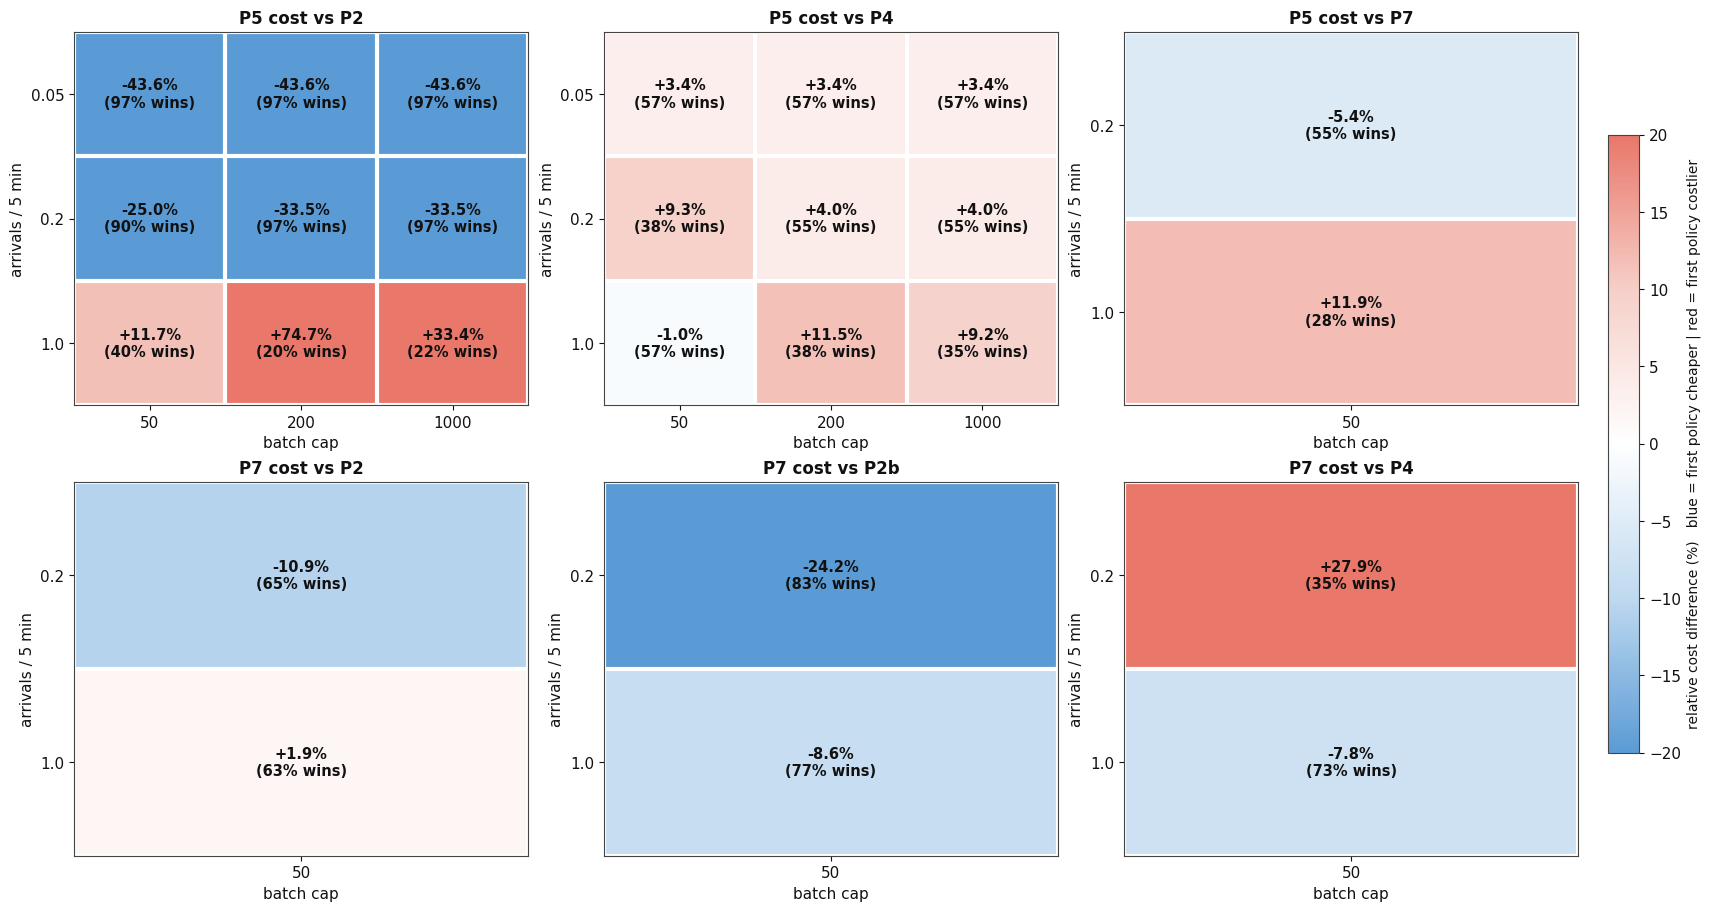

In [11]:
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
# [v7] LIGHT diverging colour map: blue = first policy cheaper, red = first policy costlier. Dark text stays readable everywhere.
LIGHT_DIV = LinearSegmentedColormap.from_list("light_div", ["#5B9BD5", "#BFD9F0", "#FFFFFF", "#F6CFC8", "#E9776A"])
NORM = TwoSlopeNorm(vcenter=0, vmin=-20, vmax=20)          # colours saturate at +/-20 %, the printed numbers stay exact

def rel_table(pa, pb):
    a = sim[sim.policy == pa].set_index(["fold", "rate", "cap", "seed"])["cost_eth"]
    b = sim[sim.policy == pb].set_index(["fold", "rate", "cap", "seed"])["cost_eth"]
    d = (100 * (a / b - 1)).rename("rel").dropna().reset_index()
    if d.empty: return None, None
    return d.groupby(["rate", "cap"])["rel"].mean().unstack("cap"), d.assign(win=lambda x: x.rel < 0).groupby(["rate", "cap"])["win"].mean().unstack("cap")

PAIRS = [("P5 Window ML", "P2 Threshold (no ML)"), ("P5 Window ML", "P4 Window hour prior"), ("P5 Window ML", "P7 RL (Q-learning)"),
         ("P7 RL (Q-learning)", "P2 Threshold (no ML)"), ("P7 RL (Q-learning)", "P2b Fee-dep. queue threshold"), ("P7 RL (Q-learning)", "P4 Window hour prior")]
fig, axes = plt.subplots(2, 3, figsize=(17, 9), facecolor="white", constrained_layout=True)
im = None
for ax, (pa, pb) in zip(axes.ravel(), PAIRS):
    rel, wins = rel_table(pa, pb)
    ax.set_facecolor("white")
    if rel is None:
        ax.axis("off"); ax.set_title(f"{pa.split(' ')[0]} vs {pb.split(' ')[0]}: no data", fontsize=11); continue
    im = ax.imshow(rel.values, cmap=LIGHT_DIV, norm=NORM, aspect="auto")
    ax.set_xticks(range(len(rel.columns))); ax.set_xticklabels(rel.columns, fontsize=11)
    ax.set_yticks(range(len(rel.index))); ax.set_yticklabels(rel.index, fontsize=11)
    ax.set_xticks(np.arange(-.5, rel.shape[1], 1), minor=True); ax.set_yticks(np.arange(-.5, rel.shape[0], 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=3); ax.tick_params(which="minor", length=0)
    for i in range(rel.shape[0]):
        for j in range(rel.shape[1]):
            v = rel.values[i, j]
            if np.isnan(v): continue
            ax.text(j, i, f"{v:+.1f}%\n({100 * wins.values[i, j]:.0f}% wins)", ha="center", va="center", fontsize=10.5, color="#111111", fontweight="bold")
    ax.set_title(f"{pa.split(' ')[0]} cost vs {pb.split(' ')[0]}", fontsize=12, fontweight="bold")
    ax.set_xlabel("batch cap", fontsize=11); ax.set_ylabel("arrivals / 5 min", fontsize=11)
if im is not None:
    cb = fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.75, pad=0.02)
    cb.set_label("relative cost difference (%)   blue = first policy cheaper | red = first policy costlier", fontsize=10)
fig.savefig(ART / "fig_rel_cost_heatmap.png", dpi=300, bbox_inches="tight"); plt.show()

### 7b-2. [v7] Paired uncertainty for the key comparisons (main configuration)
The resampling unit is the fold, because seeds share one fee path. P8 is included on purpose: if even the clairvoyant policy barely beats the simple rules, timing has little headroom here, whatever model is used.

In [12]:
def paired_table(pairs, rate=MAIN_RATE, cap=MAIN_CAP, B=5000):
    """Paired bootstrap over FOLDS (seeds share one fee path, so they are not independent). Negative = first policy cheaper / faster."""
    rng = np.random.default_rng(SEED); rows = []; m = sim[(sim.rate == rate) & (sim.cap == cap)]
    ci = lambda x: np.percentile([x[rng.integers(0, len(x), len(x))].mean() for _ in range(B)], [2.5, 97.5])
    for pa, pb in pairs:
        a = m[m.policy == pa].groupby(["fold", "seed"])[["cost_eth", "avg_wait_min"]].mean()
        b = m[m.policy == pb].groupby(["fold", "seed"])[["cost_eth", "avg_wait_min"]].mean()
        if a.empty or b.empty: continue
        rel = (100 * (a.cost_eth / b.cost_eth - 1)).groupby("fold").mean().values
        dw = (a.avg_wait_min - b.avg_wait_min).groupby("fold").mean().values
        lo_c, hi_c = ci(rel); lo_w, hi_w = ci(dw)
        rows.append({"A": pa.split(" ")[0], "B": pb.split(" ")[0], "folds": len(rel), "cost diff % (A vs B)": round(rel.mean(), 2),
                     "cost 95% CI": f"[{lo_c:+.1f}, {hi_c:+.1f}]", "A cheaper in folds": int((rel < 0).sum()),
                     "wait diff (min)": round(dw.mean(), 1), "wait 95% CI": f"[{lo_w:+.1f}, {hi_w:+.1f}]"})
    return pd.DataFrame(rows)

KEY_PAIRS = [("P5 Window ML", "P4 Window hour prior"), ("P5 Window ML", "P2 Threshold (no ML)"), ("P7 RL (Q-learning)", "P1 Fixed 12 h"),
             ("P2 Threshold (no ML)", "P1 Fixed 12 h"), ("P8 Clairvoyant (future-fee)", "P2 Threshold (no ML)"),
             ("P8 Clairvoyant (future-fee)", "P4 Window hour prior"), ("P6 Window oracle label", "P4 Window hour prior")]
pt = paired_table(KEY_PAIRS); display(pt); pt.to_csv(ART / "paired_cost_wait_ci.csv", index=False)
print("Reading guide: if a CI contains 0 the difference is not distinguishable from noise. P8 vs P2/P4 is the timing-headroom check:",
      "a small negative number means even perfect future knowledge adds little on top of simple rules.")

,A,B,folds,cost diff % (A vs B),cost 95% CI,A cheaper in folds,wait diff (min),wait 95% CI
0,P5,P4,20,-1.04,"[-3.4, +2.3]",14,-0.3,"[-0.8, +0.1]"
1,P5,P2,20,11.70,"[+2.2, +23.4]",5,11.3,"[+10.1, +12.8]"
2,P7,P1,20,6.85,"[+1.0, +16.5]",3,-7.3,"[-15.7, -0.4]"
3,P2,P1,20,9.23,"[+5.4, +13.6]",3,-25.7,"[-27.2, -24.3]"
4,P8,P2,20,-17.46,"[-21.0, -14.1]",20,13.8,"[+12.1, +15.7]"
5,P8,P4,20,-23.90,"[-28.9, -19.9]",20,2.1,"[+1.4, +2.9]"
6,P6,P4,20,4.75,"[+0.8, +8.7]",5,-2.1,"[-2.8, -1.4]"


Reading guide: if a CI contains 0 the difference is not distinguishable from noise. P8 vs P2/P4 is the timing-headroom check: a small negative number means even perfect future knowledge adds little on top of simple rules.


### 7c. Cost against wait (mean over folds and seeds)
The cheapest policy is not always the best one, since waiting longer can lower cost. Labels are policy IDs; P0 is off the scale.

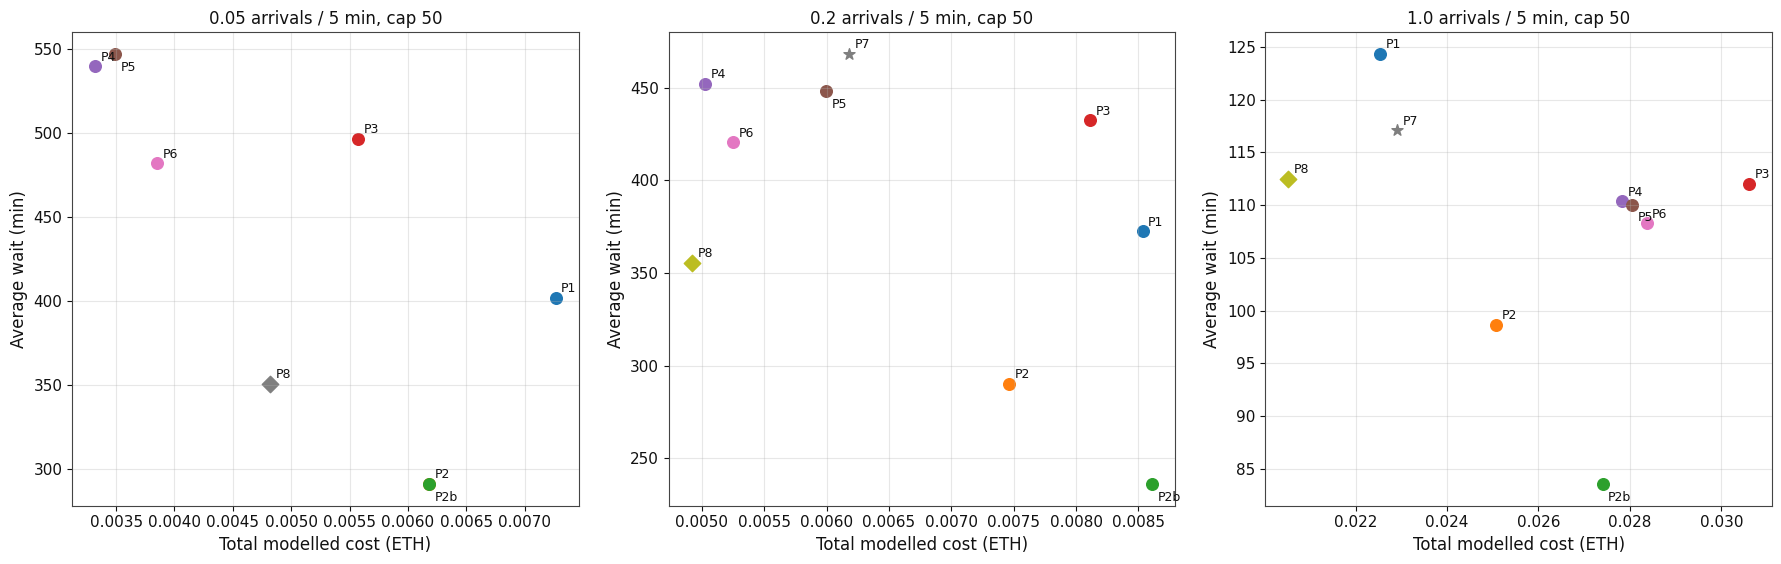

avg wait (min) at rate,0.05,0.20,1.00
policy,,,
P1 Fixed 12 h,401.7,372.6,124.3
P2 Threshold (no ML),290.8,290.4,98.7
P2b Fee-dep. queue threshold,290.8,236.1,83.5
P3 Window random,496.5,432.4,112.0
P4 Window hour prior,539.6,452.1,110.4
P5 Window ML,547.0,448.2,110.0
P6 Window oracle label,481.8,420.7,108.3
P7 RL (Q-learning),NaN,468.3,117.1
P8 Clairvoyant (future-fee),350.7,355.6,112.5


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.8), facecolor="white")
cw_rows = []
for ax, rate in zip(axes, RATES):
    g = sim[(sim.rate == rate) & (sim.cap == MAIN_CAP) & (sim.policy != "P0 Immediate")].groupby("policy")[["cost_eth", "avg_wait_min"]].mean()
    for name, r in g.iterrows():
        ax.scatter(r.cost_eth, r.avg_wait_min, s=70, marker="*" if name.startswith("P7") else ("D" if name.startswith("P8") else "o"))
        off = (4, -12) if name.startswith(("P2b", "P5")) else (4, 4)
        ax.annotate(name.split(" ")[0], (r.cost_eth, r.avg_wait_min), xytext=off, textcoords="offset points", fontsize=9)
        cw_rows.append({"rate": rate, "cap": MAIN_CAP, "policy": name, "cost_eth": r.cost_eth, "avg_wait_min": r.avg_wait_min})
    ax.set_xlabel("Total modelled cost (ETH)"); ax.set_ylabel("Average wait (min)"); ax.set_title(f"{rate} arrivals / 5 min, cap {MAIN_CAP}"); ax.grid(alpha=.3)
plt.tight_layout(); fig.savefig(ART / "fig_cost_vs_wait.png", dpi=300, bbox_inches="tight"); plt.show()
cw = pd.DataFrame(cw_rows); cw.to_csv(ART / "cost_vs_wait_points.csv", index=False)   # [v7] quote these exact numbers in the paper, not values read off the plot
display(cw.pivot(index="policy", columns="rate", values="avg_wait_min").round(1).rename_axis(columns="avg wait (min) at rate"))

In [14]:
sim[sim.policy.str.startswith("P7")].groupby(["rate","cap"]).size()

,,0
rate,cap,
0.2,50,60
1.0,50,60


### 7d-2. [v7] Who triggers each anchor?
The SLA guard, a full queue, or the policy itself. If P7's policy-initiated share is close to 0 %, its results come from the guard and the full-queue rule, not from anything the agent learned.

In [15]:
def anchor_reasons(batches, arr, cap):
    """Classify every anchor exactly as the scheduler would: SLA guard first, then full queue, else the policy trigger."""
    cnt = {"guard": 0, "full": 0, "policy_rule": 0}
    for t, a, b in batches:
        q = int(np.searchsorted(arr, t, side="right")) - a
        if (t - arr[a]) >= SLA_STEPS - GUARD_STEPS: cnt["guard"] += 1
        elif q >= cap: cnt["full"] += 1
        else: cnt["policy_rule"] += 1
    return cnt

rows = []
for (name, fs, sd), bt in STORE.items():
    if name == "arr" or bt is None: continue
    c = anchor_reasons(bt, STORE[("arr", fs, sd)], MAIN_CAP); rows.append({"policy": name, **c})
rs = pd.DataFrame(rows).groupby("policy").sum()
rs["policy-initiated %"] = (100 * rs["policy_rule"] / rs[["guard", "full", "policy_rule"]].sum(1)).round(1)
print("Who triggered the anchors (main configuration, summed over folds and seeds):"); display(rs)
rs.to_csv(ART / "anchor_triggers_main.csv")

# share of visited RL states whose greedy action is WAIT (last fold, main configuration)
for fs in [fold_data[0]["fs"], fold_data[-1]["fs"]]:
    Qx = QSTORE.get((fs, MAIN_RATE, MAIN_CAP))
    if Qx is None: continue
    vis = Qx.any(axis=1)
    print(f"fold {fs}: visited RL states = {int(vis.sum())}/{N_STATES}; greedy WAIT in {100 * (Qx[vis].argmax(1) == 0).mean():.0f}% of visited states")

Who triggered the anchors (main configuration, summed over folds and seeds):


,guard,full,policy_rule,policy-initiated %
policy,,,,
P1 Fixed 12 h,0,10096,60,0.6
P2 Threshold (no ML),44,5227,8496,61.7
P2b Fee-dep. queue threshold,52,2902,13235,81.8
P3 Window random,4,7794,6644,46.0
P4 Window hour prior,0,7625,6202,44.9
P5 Window ML,0,7626,6165,44.7
P6 Window oracle label,1,7219,7243,50.1
P7 RL (Q-learning),21,8652,2996,25.7
P8 Clairvoyant (future-fee),39,7189,4363,37.6


fold 2025-01-01: visited RL states = 24/36; greedy WAIT in 75% of visited states
fold 2026-08-01: visited RL states = 24/36; greedy WAIT in 88% of visited states


### 7e. Gas-assumption sensitivity (main configuration)

In [16]:
sens = []
for pc in sorted({0, 2000, 5000, int(PER_CRED_GAS)}):
    for name in ["P1 Fixed 12 h", "P2 Threshold (no ML)", "P2b Fee-dep. queue threshold", "P4 Window hour prior", "P5 Window ML", "P7 RL (Q-learning)", "P8 Clairvoyant (future-fee)"]:
        reds = []
        for f in fold_data:
            for sd in SEEDS_SWEEP:
                arr = STORE.get(("arr", f["fs"], sd))
                if arr is None or STORE.get((name, f["fs"], sd)) is None: continue
                c0 = evaluate_immediate(arr, fee)["cost_eth"]; reds.append(100 * (1 - evaluate(STORE[(name, f["fs"], sd)], arr, fee, per_cred_gas=pc)["cost_eth"] / c0))
        sens.append({"extra_gas_per_cert": pc, "policy": name, "reduction_pct": np.mean(reds)})
sens_tbl = pd.DataFrame(sens).pivot(index="policy", columns="extra_gas_per_cert", values="reduction_pct").round(2)
display(sens_tbl); sens_tbl.to_csv(ART / "gas_sensitivity.csv")

extra_gas_per_cert,0,2000,5000
policy,,,
P1 Fixed 12 h,97.79,95.58,92.26
P2 Threshold (no ML),97.63,95.56,92.44
P2b Fee-dep. queue threshold,97.41,95.38,92.34
P4 Window hour prior,97.38,95.17,91.86
P5 Window ML,97.44,95.23,91.93
P7 RL (Q-learning),97.67,95.52,92.30
P8 Clairvoyant (future-fee),98.08,96.28,93.58


### 7f. [v9] Cost-delay frontier, RL spread across seeds, reference policies per workload
Every tunable candidate (rule settings, RL delay weight × independent seed) is scored on a validation block and on the test folds. This section shows the test-fold frontier; the validation-based choice is in 7f-2. RL points are mean ± sd over independent trainings.

In [17]:
# ---------- arrival generators: gen(rng, lo, hi) -> sorted int array of arrival steps in [lo, hi)
def poisson_gen(rate):
    return lambda rng, lo, hi: np.repeat(np.arange(lo, hi), rng.poisson(rate, hi - lo))

def bursty_gen(rng, lo, hi, base_rate=0.2, burst_prob=0.15, burst_mean=300, burst_steps=36):
    """Poisson background + occasional bulk-issue bursts (e.g. results day): ~15 % of days get ~300 certificates within 3 h."""
    parts = [np.repeat(np.arange(lo, hi), rng.poisson(base_rate, hi - lo))]
    for d in range((hi - lo) // 288):
        if rng.random() < burst_prob:
            parts.append(lo + d * 288 + rng.integers(0, 288 - burst_steps) + rng.integers(0, burst_steps, rng.poisson(burst_mean)))
    return np.sort(np.concatenate(parts))

WORKLOADS = {
    f"poisson {MAIN_RATE}/step": dict(kind="poisson", rate=MAIN_RATE, cap=MAIN_CAP, gen=poisson_gen(MAIN_RATE), rng=lambda fi, k: np.random.default_rng(k)),
    "bursty 0.2/step + bursts": dict(kind="bursty", rate=0.2, cap=50, gen=bursty_gen, rng=lambda fi, k: np.random.default_rng([1000, fi, k])),
}
if Path(ISSUANCE_CSV).exists():      # optional REAL issuance trace, replayed (tiled) into every fold so it meets every fee regime
    tr_ = pd.to_datetime(pd.read_csv(ISSUANCE_CSV).iloc[:, 0], utc=True).sort_values()
    off_ = ((tr_ - tr_.min().floor("D")).dt.total_seconds().values // (STEP_MIN * 60)).astype(int)
    period_ = int(np.ceil((off_.max() + 1) / 288) * 288)
    def gen_real(rng, lo, hi):
        a_ = np.sort(np.concatenate([lo + k * period_ + off_ for k in range(int(np.ceil((hi - lo) / period_)))])); return a_[a_ < hi]
    WORKLOADS[f"real trace ({len(off_)} certs, {period_ // 288} d)"] = dict(kind="real", rate=len(off_) / period_, cap=MAIN_CAP, gen=gen_real,
                                                                           rng=lambda fi, k: np.random.default_rng(k), reps=[SEEDS_SWEEP[0]])
    print(f"Real issuance trace found: {len(off_)} certificates replayed.")
else:
    print(f"No {ISSUANCE_CSV}: only synthetic workloads (Poisson, bursty). A real trace would strengthen the paper a lot.")

def _run(arr, cfg, cap, mb, lo, hi):
    if cfg is None: return evaluate_immediate(arr, fee)
    bt, left = run_scheduler(fee, thr, thr2, arr, cap=cap, min_batch=mb, start=lo, end=hi, **cfg)
    assert left == 0, "certificates left unanchored"
    r = evaluate(bt, arr, fee); assert r["_max_wait"] <= SLA_STEPS, "SLA breached"; return r

def sweep_workload(wname, spec):
    """Every tunable candidate (rules, RL delay x seed) is run on the VALIDATION block (ends one SLA before the fold) and on the TEST fold."""
    rate, cap, gen, mkrng = spec["rate"], spec["cap"], spec["gen"], spec["rng"]; reps = spec.get("reps", SEEDS_SWEEP)
    mb = min_batch_for(rate, cap); rows = []; t0 = time.time()
    for fi, f in enumerate(fold_data):
        lo, hi = f["lo"], f["hi"]; last = hi - SLA_STEPS - 1
        val_lo, val_hi = lo - VAL_DAYS * 288 - SLA_STEPS, lo - SLA_STEPS
        assert val_hi + SLA_STEPS <= lo and val_lo > THR_LOOKBACK, "validation block must end before the fold"
        varr = gen(mkrng(fi, 7), val_lo, val_hi - SLA_STEPS - 1); tarr = [gen(mkrng(fi, sd), lo, last) for sd in reps]
        c0 = float(np.mean([evaluate_immediate(a, fee)["cost_eth"] for a in tarr]))
        def add(fam, setting, cfg, mbx=mb, tune=True, rl_seed=-1, delay=np.nan):
            tr = [_run(a, cfg, cap, mbx, lo, hi) for a in tarr]; vr = _run(varr, cfg, cap, mbx, val_lo, val_hi) if tune else None
            rows.append({"workload": wname, "fold": f["fs"], "family": fam, "setting": setting, "rl_seed": rl_seed, "delay": delay,
                         "val_cost": vr["cost_eth"] if vr else np.nan, "val_wait": vr["avg_wait_min"] if vr else np.nan,
                         "test_cost": float(np.mean([r["cost_eth"] for r in tr])), "test_wait": float(np.mean([r["avg_wait_min"] for r in tr])),
                         "test_tx": float(np.mean([r["transactions"] for r in tr])), "test_cost_immediate": c0})
        for name, cfg in policies(fold_plans(f)).items(): add("ref", name, cfg, tune=False)      # untuned reference policies (test only)
        for iv in RULE_INTERVALS: add("P1 fixed interval", f"{iv * STEP_MIN / 60:g} h", dict(mode="fixed", interval=iv))
        for m_ in RULE_MINB:
            if m_ <= cap:
                add("P2 threshold", f"min_batch={m_}", dict(mode="threshold"), mbx=m_); add("P2b fee-dep. queue", f"min_batch={m_}", dict(mode="qfee"), mbx=m_)
        for d in RL_DELAY_GRID:
            for s in range(RL_N_SEEDS):
                Qd, _ = train_rl(fi, f, rate, cap, mb, delay=d, rl_seed=s, gen=gen)
                add("P7 RL", f"delay={d:g}", dict(mode="rl", qtab=Qd), rl_seed=s, delay=d)
        print(f"  [{wname}] fold {f['fs']} done ({time.time() - t0:.0f}s)")
    return pd.DataFrame(rows)

cand = pd.concat([sweep_workload(n, s) for n, s in WORKLOADS.items()], ignore_index=True)
cand.to_csv(ART / "candidates_all.csv", index=False)
print(f"{len(cand):,} candidate evaluations (validation + test) over {len(WORKLOADS)} workload(s)")

No issuance_times.csv: only synthetic workloads (Poisson, bursty). A real trace would strengthen the paper a lot.
  [poisson 1.0/step] fold 2025-01-01 done (93s)
  [poisson 1.0/step] fold 2025-02-01 done (185s)
  [poisson 1.0/step] fold 2025-03-01 done (279s)
  [poisson 1.0/step] fold 2025-04-01 done (371s)
  [poisson 1.0/step] fold 2025-05-01 done (463s)
  [poisson 1.0/step] fold 2025-06-01 done (556s)
  [poisson 1.0/step] fold 2025-07-01 done (649s)
  [poisson 1.0/step] fold 2025-08-01 done (742s)
  [poisson 1.0/step] fold 2025-09-01 done (835s)
  [poisson 1.0/step] fold 2025-10-01 done (928s)
  [poisson 1.0/step] fold 2025-11-01 done (1020s)
  [poisson 1.0/step] fold 2025-12-01 done (1112s)
  [poisson 1.0/step] fold 2026-01-01 done (1204s)
  [poisson 1.0/step] fold 2026-02-01 done (1297s)
  [poisson 1.0/step] fold 2026-03-01 done (1389s)
  [poisson 1.0/step] fold 2026-04-01 done (1482s)
  [poisson 1.0/step] fold 2026-05-01 done (1574s)
  [poisson 1.0/step] fold 2026-06-01 done (1665

RL: mean and spread (sd over independent training seeds) per delay setting


,workload,family,setting,cost_eth,cost_sd_over_rl_seeds,wait_min,wait_sd_over_rl_seeds,transactions
29,bursty 0.2/step + bursts,P7 RL,delay=0.0005,0.0119,0.0007,304.0730,11.7186,99.0100
30,bursty 0.2/step + bursts,P7 RL,delay=0.002,0.0118,0.0002,279.8814,10.1885,105.7100
31,bursty 0.2/step + bursts,P7 RL,delay=0.005,0.0177,0.0016,189.9351,12.2106,163.6267
32,bursty 0.2/step + bursts,P7 RL,delay=0.02,0.0306,0.0070,140.2969,13.9077,223.7100
33,bursty 0.2/step + bursts,P7 RL,delay=0.05,0.0257,0.0074,166.6756,33.6753,205.7900
63,poisson 1.0/step,P7 RL,delay=0.0005,0.0228,0.0001,123.3254,1.3279,179.5433
64,poisson 1.0/step,P7 RL,delay=0.002,0.0229,0.0002,121.6815,1.6816,179.7033
65,poisson 1.0/step,P7 RL,delay=0.005,0.0231,0.0003,120.5073,3.7598,184.0867
66,poisson 1.0/step,P7 RL,delay=0.02,0.0235,0.0009,119.7338,2.0301,192.2167
67,poisson 1.0/step,P7 RL,delay=0.05,0.0280,0.0051,112.7886,3.3691,326.3800



Untuned reference policies per workload (P0-P6, P8 at default settings):


cost_eth  avg_wait_min  \
workload                 setting                                                
bursty 0.2/step + bursts P0 Immediate                    0.4125        0.0000   
                         P1 Fixed 12 h                   0.0119      233.2804   
                         P2 Threshold (no ML)            0.0131      174.9041   
                         P2b Fee-dep. queue threshold    0.0142      141.9638   
                         P3 Window random                0.0134      257.4252   
                         P4 Window hour prior            0.0113      273.3495   
                         P5 Window ML                    0.0109      271.9677   
                         P6 Window oracle label          0.0126      250.6129   
                         P8 Clairvoyant (future-fee)     0.0099      214.1112   
poisson 1.0/step         P0 Immediate                    1.0128        0.0000   
                         P1 Fixed 12 h                   0.0225      124.3420   
                         P2 Threshold (no ML)            0.0251       98.6834   
                         P2b Fee-dep. queue threshold    0.0274       83.5434   
                         P3 Window random                0.0306      112.0326   
                         P4 Window hour prior            0.0278      110.3724   
                         P5 Window ML                    0.0280      110.0302   
                         P6 Window oracle label          0.0284      108.2718   
                         P8 Clairvoyant (future-fee)     0.0205      112.5220   

                                                       transactions  \
workload                 setting                                      
bursty 0.2/step + bursts P0 Immediate                     2957.0333   
                         P1 Fixed 12 h                      80.2500   
                         P2 Threshold (no ML)              170.0833   
                         P2b Fee-dep. queue threshold      184.9500   
                         P3 Window random                  106.8333   
                         P4 Window hour prior              108.1333   
                         P5 Window ML                      108.0000   
                         P6 Window oracle label            120.3500   
                         P8 Clairvoyant (future-fee)       112.9333   
poisson 1.0/step         P0 Immediate                     8439.5333   
                         P1 Fixed 12 h                     169.2667   
                         P2 Threshold (no ML)              229.4500   
                         P2b Fee-dep. queue threshold      269.8167   
                         P3 Window random                  240.7000   
                         P4 Window hour prior              230.4500   
                         P5 Window ML                      229.8500   
                         P6 Window oracle label            241.0500   
                         P8 Clairvoyant (future-fee)       193.1833   

                                                       reduction_pct  
workload                 setting                                      
bursty 0.2/step + bursts P0 Immediate                         0.0000  
                         P1 Fixed 12 h                       97.1247  
                         P2 Threshold (no ML)                96.8350  
                         P2b Fee-dep. queue threshold        96.5574  
                         P3 Window random                    96.7470  
                         P4 Window hour prior                97.2615  
                         P5 Window ML                        97.3652  
                         P6 Window oracle label              96.9373  
                         P8 Clairvoyant (future-fee)         97.6071  
poisson 1.0/step         P0 Immediate                         0.0000  
                         P1 Fixed 12 h                       97.7752  
                         P2 Threshold (no ML)                97.5241  
                   

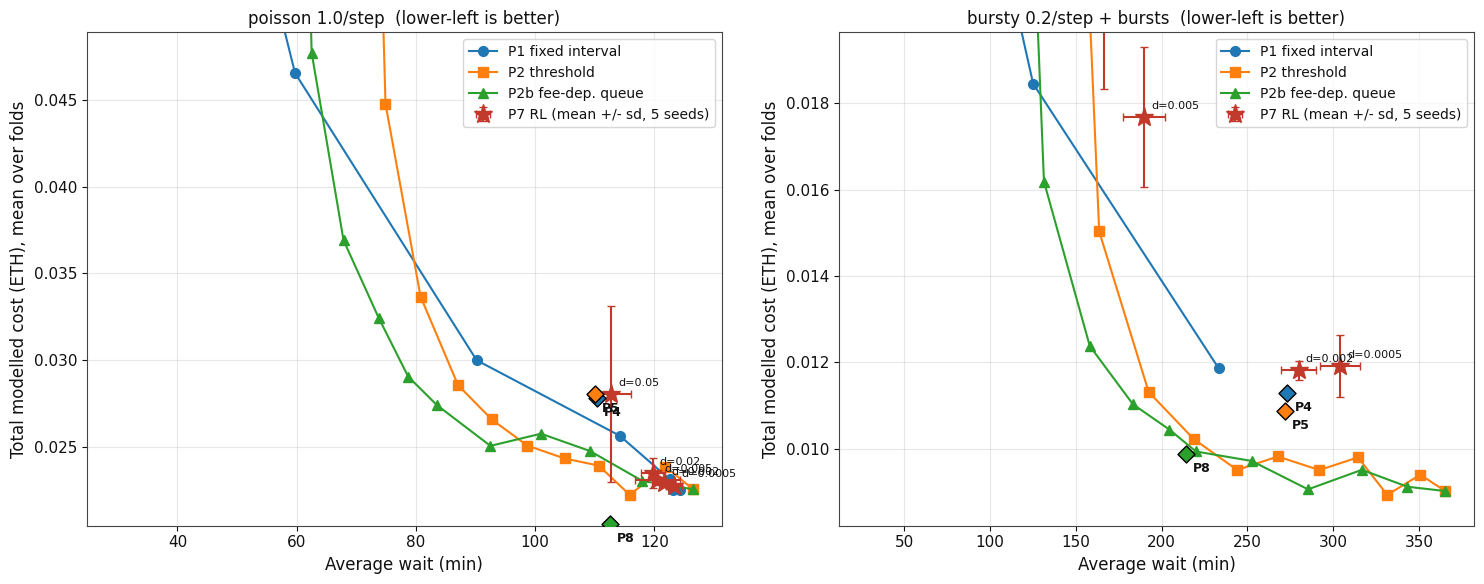

In [18]:
FAM_RULES = ["P1 fixed interval", "P2 threshold", "P2b fee-dep. queue"]
ct = cand[cand.family != "ref"]
fm = ct.groupby(["workload", "family", "setting", "rl_seed"])[["test_cost", "test_wait", "test_tx"]].mean().reset_index()      # mean over folds first
fr = (fm.groupby(["workload", "family", "setting"], sort=False)
        .agg(cost_eth=("test_cost", "mean"), cost_sd_over_rl_seeds=("test_cost", "std"), wait_min=("test_wait", "mean"), wait_sd_over_rl_seeds=("test_wait", "std"),
             transactions=("test_tx", "mean")).reset_index())
fr.to_csv(ART / "frontier_all.csv", index=False)
print("RL: mean and spread (sd over independent training seeds) per delay setting"); rl_spread = fr[fr.family == "P7 RL"].round(4); display(rl_spread); rl_spread.to_csv(ART / "rl_delay_spread.csv", index=False)

ref_tbl = cand[cand.family == "ref"].groupby(["workload", "setting"])[["test_cost", "test_wait", "test_tx", "test_cost_immediate"]].mean()
ref_tbl["reduction_pct"] = 100 * (1 - ref_tbl.test_cost / ref_tbl.test_cost_immediate)
ref_tbl = ref_tbl.rename(columns={"test_cost": "cost_eth", "test_wait": "avg_wait_min", "test_tx": "transactions"}).drop(columns="test_cost_immediate")
print("\nUntuned reference policies per workload (P0-P6, P8 at default settings):"); display(ref_tbl.round(4)); ref_tbl.to_csv(ART / "workload_reference_policies.csv")

fig, axes = plt.subplots(1, len(WORKLOADS), figsize=(7.5 * len(WORKLOADS), 6), facecolor="white", squeeze=False)
for ax, wname in zip(axes[0], WORKLOADS):
    g = fr[fr.workload == wname]
    for fam, mk in zip(FAM_RULES, ["o", "s", "^"]):
        h = g[g.family == fam].sort_values("wait_min"); ax.plot(h.wait_min, h.cost_eth, marker=mk, lw=1.5, ms=7, label=fam)
    h = g[g.family == "P7 RL"]
    ax.errorbar(h.wait_min, h.cost_eth, xerr=h.wait_sd_over_rl_seeds.fillna(0), yerr=h.cost_sd_over_rl_seeds.fillna(0), fmt="*", ms=14, capsize=3, color="#C0392B",
                label=f"P7 RL (mean +/- sd, {RL_N_SEEDS} seeds)")
    for _, r in h.iterrows(): ax.annotate(r.setting.replace("delay=", "d="), (r.wait_min, r.cost_eth), xytext=(5, 6), textcoords="offset points", fontsize=8)
    for pn in ["P4 Window hour prior", "P5 Window ML", "P8 Clairvoyant (future-fee)"]:
        if (wname, pn) in ref_tbl.index:
            r = ref_tbl.loc[(wname, pn)]; ax.scatter(r.avg_wait_min, r.cost_eth, marker="D", s=75, edgecolor="black", zorder=5)
            ax.annotate(pn.split(" ")[0], (r.avg_wait_min, r.cost_eth), xytext=(5, -13), textcoords="offset points", fontsize=9, fontweight="bold")
    ax.set_ylim(g.cost_eth.min() * 0.92, g.cost_eth.min() * 2.2)      # focus on the competitive region; expensive small-batch settings are clipped
    ax.set_xlabel("Average wait (min)"); ax.set_ylabel("Total modelled cost (ETH), mean over folds"); ax.grid(alpha=.3); ax.legend(fontsize=10); ax.set_title(wname + "  (lower-left is better)")
plt.tight_layout(); fig.savefig(ART / "fig_frontier.png", dpi=300, bbox_inches="tight"); plt.show()

### 7f-2. [v9] Matched-budget comparison: tuned rules against RL
For each average-wait budget W, every family picks its best setting on the validation block (lowest cost with validation wait ≤ W). That setting is then scored on the test fold, and differences are paired by fold with a bootstrap over folds. This replaces the interpolation used in v8.

In [19]:
def pick(g, W):
    """Validation-only choice: lowest validation cost among candidates whose VALIDATION wait is within the budget (else the lowest-wait candidate)."""
    ok = g[g.val_wait <= W]; return ok.loc[ok.val_cost.idxmin()] if len(ok) else g.loc[g.val_wait.idxmin()]

rows = []
for wname, spec in WORKLOADS.items():
    for W in WAIT_BUDGETS[spec["kind"]]:
        for fam in FAM_RULES + ["P7 RL"]:
            for fold, g in cand[(cand.workload == wname) & (cand.family == fam)].groupby("fold"):
                p = pick(g.reset_index(drop=True), W)
                rows.append({"workload": wname, "budget_min": W, "family": fam, "fold": fold, "chosen_setting": p.setting, "chosen_rl_seed": int(p.rl_seed),
                             "feasible_on_val": bool((g.val_wait <= W).any()), "val_wait": p.val_wait, "test_cost": p.test_cost, "test_wait": p.test_wait})
mbud = pd.DataFrame(rows); mbud.to_csv(ART / "matched_budget_by_fold.csv", index=False)

def boot_ci(x, B=5000):
    rng = np.random.default_rng(SEED); m = [x[rng.integers(0, len(x), len(x))].mean() for _ in range(B)]; return np.percentile(m, [2.5, 97.5])

sum_rows, cmp_rows = [], []
for (w, W), g in mbud.groupby(["workload", "budget_min"], sort=False):
    cost = g.pivot(index="fold", columns="family", values="test_cost"); wait = g.pivot(index="fold", columns="family", values="test_wait")
    for fam in FAM_RULES + ["P7 RL"]:
        sum_rows.append({"workload": w, "budget_min": W, "family": fam, "test_cost_eth": cost[fam].mean(), "test_wait_min": wait[fam].mean(),
                         "folds_feasible_on_val": int(g[g.family == fam].feasible_on_val.sum()), "folds": len(cost)})
    best = min(FAM_RULES, key=lambda x: cost[x].mean())
    for ref_ in FAM_RULES + [f"best rule on average ({best})"]:
        col = best if ref_.startswith("best") else ref_
        d = 100 * (cost["P7 RL"] / cost[col] - 1).values; dw = (wait["P7 RL"] - wait[col]).values; lo_, hi_ = boot_ci(d)
        cmp_rows.append({"workload": w, "budget_min": W, "RL vs": ref_, "cost diff % (RL vs rule)": round(d.mean(), 2), "95% CI (folds)": f"[{lo_:+.1f}, {hi_:+.1f}]",
                         "RL cheaper in folds": f"{int((d < 0).sum())}/{len(d)}", "wait diff (min)": round(dw.mean(), 1), "_lo": lo_, "_hi": hi_, "_mean": d.mean()})
mb_summary = pd.DataFrame(sum_rows); rl_vs_rules = pd.DataFrame(cmp_rows)
mb_summary.to_csv(ART / "matched_budget_summary.csv", index=False); rl_vs_rules.drop(columns=["_lo", "_hi", "_mean"]).to_csv(ART / "matched_budget_rl_vs_rules.csv", index=False)
print("Matched-budget results: settings chosen on VALIDATION, costs and waits measured on the TEST folds (mean over folds).")
display(mb_summary.round(4)); display(rl_vs_rules.drop(columns=["_lo", "_hi", "_mean"]))
print("Reading guide: negative 'cost diff' = RL cheaper than that rule at the same wait budget. If the CI contains 0 the two are not distinguishable;",
      "'RL beats the rules' needs a CI entirely below 0 in most (workload, budget) cells. Compare 'wait diff' too: a lower cost with a much longer wait is not a win.")

Matched-budget results: settings chosen on VALIDATION, costs and waits measured on the TEST folds (mean over folds).


,workload,budget_min,family,test_cost_eth,test_wait_min,folds_feasible_on_val,folds
0,poisson 1.0/step,80,P1 fixed interval,0.0466,59.7297,20,20
1,poisson 1.0/step,80,P2 threshold,0.0437,77.6216,20,20
2,poisson 1.0/step,80,P2b fee-dep. queue,0.0302,78.9876,20,20
3,poisson 1.0/step,80,P7 RL,0.0475,79.3771,12,20
4,poisson 1.0/step,100,P1 fixed interval,0.0300,90.2012,20,20
5,poisson 1.0/step,100,P2 threshold,0.0250,96.6608,20,20
6,poisson 1.0/step,100,P2b fee-dep. queue,0.0260,95.6167,20,20
7,poisson 1.0/step,100,P7 RL,0.0379,89.8186,18,20
8,poisson 1.0/step,120,P1 fixed interval,0.0263,111.8276,20,20
9,poisson 1.0/step,120,P2 threshold,0.0230,113.8281,20,20


,workload,budget_min,RL vs,cost diff % (RL vs rule),95% CI (folds),RL cheaper in folds,wait diff (min)
0,poisson 1.0/step,80,P1 fixed interval,7.95,"[-18.4, +41.9]",10/20,19.6
1,poisson 1.0/step,80,P2 threshold,35.87,"[+4.6, +72.3]",7/20,1.8
2,poisson 1.0/step,80,P2b fee-dep. queue,76.64,"[+36.6, +126.1]",3/20,0.4
3,poisson 1.0/step,80,best rule on average (P2b fee-dep. queue),76.64,"[+36.6, +126.1]",3/20,0.4
4,poisson 1.0/step,100,P1 fixed interval,16.57,"[-8.0, +48.0]",13/20,-0.4
5,poisson 1.0/step,100,P2 threshold,42.64,"[+13.3, +80.3]",5/20,-6.8
6,poisson 1.0/step,100,P2b fee-dep. queue,41.31,"[+11.2, +81.0]",5/20,-5.8
7,poisson 1.0/step,100,best rule on average (P2 threshold),42.64,"[+13.3, +80.3]",5/20,-6.8
8,poisson 1.0/step,120,P1 fixed interval,32.31,"[+2.3, +71.0]",7/20,-20.9
9,poisson 1.0/step,120,P2 threshold,52.59,"[+19.8, +92.6]",2/20,-22.9


Reading guide: negative 'cost diff' = RL cheaper than that rule at the same wait budget. If the CI contains 0 the two are not distinguishable; 'RL beats the rules' needs a CI entirely below 0 in most (workload, budget) cells. Compare 'wait diff' too: a lower cost with a much longer wait is not a win.


### 7h. [v10] SLA sensitivity (6, 12, 24 and 48 h)
24 h stays the primary setting. This section only checks whether the conclusions depend on it, by rerunning the main configuration (1 certificate per 5 min, cap 50) for each deadline. P1's interval is SLA/2, one RL agent is trained per fold and SLA, and everything else is unchanged. Matched-budget RL-versus-rules comparisons are done at 24 h only.

In [20]:
# [v10] SLA sensitivity (main configuration only). Only SLA_STEPS and the P1 interval change; window length (6 h), the classifier and the
# 24-h fee features stay as in the main study. The globals are restored in `finally`, so nothing above is affected.
def sla_run(sla_h):
    global SLA_STEPS, FIXED_INTERVAL_STEPS
    saved = (SLA_STEPS, FIXED_INTERVAL_STEPS); out = []
    SLA_STEPS = int(sla_h * 60 // STEP_MIN); FIXED_INTERVAL_STEPS = SLA_STEPS // 2          # P1 interval = SLA/2 (12 h when SLA = 24 h)
    try:
        mb = min_batch_for(MAIN_RATE, MAIN_CAP); gen = poisson_gen(MAIN_RATE)
        for fi, f in enumerate(fold_data):
            lo, hi = f["lo"], f["hi"]; last = hi - SLA_STEPS - 1; POL = policies(fold_plans(f))
            if SLA_SENS_RL:
                Qs, _ = train_rl(fi, f, MAIN_RATE, MAIN_CAP, mb, gen=gen); POL["P7 RL (Q-learning)"] = dict(mode="rl", qtab=Qs)
            for sd in SEEDS_SWEEP:
                arr = gen(np.random.default_rng(sd), lo, last); c0 = evaluate_immediate(arr, fee)["cost_eth"]
                for name, cfg in POL.items():
                    r = _run(arr, cfg, MAIN_CAP, mb, lo, hi)
                    out.append({"sla_h": sla_h, "fold": f["fs"], "seed": sd, "policy": "P1 Fixed SLA/2" if name.startswith("P1") else name,
                                "cost_eth": r["cost_eth"], "avg_wait_min": r["avg_wait_min"], "sla_pct": r["sla_pct"], "transactions": r["transactions"],
                                "reduction_pct": 100 * (1 - r["cost_eth"] / c0)})
    finally:
        SLA_STEPS, FIXED_INTERVAL_STEPS = saved
    return out

_t0 = time.time(); rows_ = []
for h_ in SLA_SENS_HOURS:
    rows_ += sla_run(h_); print(f"SLA {h_} h done ({time.time() - _t0:.0f}s)")
sla_df = pd.DataFrame(rows_); sla_df.to_csv(ART / "sla_sensitivity_all.csv", index=False)
assert SLA_STEPS == SLA_HOURS * 60 // STEP_MIN, "SLA_STEPS was not restored"
assert (sla_df.sla_pct == 100).all(), "SLA breached in the sensitivity runs"
if SLA_HOURS in SLA_SENS_HOURS:          # consistency check: the primary setting must reproduce the main table
    a_ = sla_df[sla_df.sla_h == SLA_HOURS].assign(policy=lambda d: d.policy.str.replace("P1 Fixed SLA/2", "P1 Fixed 12 h")).groupby("policy").cost_eth.mean()
    dev_ = float(((a_ - summ.cost_eth.reindex(a_.index)).abs() / summ.cost_eth.reindex(a_.index)).max())
    print(f"Consistency check: {SLA_HOURS} h row vs main table, max relative cost deviation = {dev_:.2e}", "(OK)" if dev_ < 1e-6 else "(WARNING: differs from the main table)")

SLA 6 h done (80s)
SLA 12 h done (160s)
SLA 24 h done (245s)
SLA 48 h done (325s)
Consistency check: 24 h row vs main table, max relative cost deviation = 0.00e+00 (OK)


Cost reduction vs immediate anchoring (%), by SLA:


sla_h,6,12,24,48
policy,,,,
P1 Fixed SLA/2,96.96,97.70,97.79,97.80
P2 Threshold (no ML),97.63,97.63,97.63,97.64
P2b Fee-dep. queue threshold,97.39,97.40,97.41,97.41
P3 Window random,97.11,97.10,97.11,97.10
P4 Window hour prior,97.35,97.37,97.38,97.37
P5 Window ML,97.42,97.41,97.44,97.44
P6 Window oracle label,97.33,97.35,97.36,97.36
P7 RL (Q-learning),97.22,97.72,97.67,97.77
P8 Clairvoyant (future-fee),98.07,98.07,98.08,98.09


Average wait (min), by SLA:


sla_h,6,12,24,48
policy,,,,
P1 Fixed SLA/2,90.2,123.2,124.3,126.5
P2 Threshold (no ML),97.6,98.3,98.7,100.4
P2b Fee-dep. queue threshold,82.2,82.6,83.5,84.7
P3 Window random,111.1,112.0,112.0,112.0
P4 Window hour prior,110.0,111.1,110.4,110.4
P5 Window ML,109.8,110.8,110.0,110.0
P6 Window oracle label,107.8,108.7,108.3,108.3
P7 RL (Q-learning),119.3,118.7,117.1,124.3
P8 Clairvoyant (future-fee),111.4,111.7,112.5,112.9


Total modelled cost (ETH), by SLA:


sla_h,6,12,24,48
policy,,,,
P1 Fixed SLA/2,0.0306,0.0228,0.0225,0.0220
P2 Threshold (no ML),0.0255,0.0253,0.0251,0.0245
P2b Fee-dep. queue threshold,0.0279,0.0276,0.0274,0.0268
P3 Window random,0.0309,0.0308,0.0306,0.0298
P4 Window hour prior,0.0285,0.0281,0.0278,0.0273
P5 Window ML,0.0285,0.0283,0.0280,0.0275
P6 Window oracle label,0.0290,0.0286,0.0284,0.0278
P7 RL (Q-learning),0.0278,0.0229,0.0229,0.0222
P8 Clairvoyant (future-fee),0.0209,0.0207,0.0205,0.0200


,SLA (h),reduction range (%),P8 gap over best realistic (pp),cheapest realistic policy,P2b vs P1,P7 (RL) vs P1,P5 (ML) vs P4,min SLA compliance (%)
0,6,96.96-98.07,0.44,P2,"-12.5% [-17.0, -8.2], wait -8.0 min","-7.2% [-16.1, +2.7], wait +29.1 min","-1.5% [-3.9, +1.7], wait -0.2 min",100.0
1,12,97.10-98.07,0.35,P1,"+16.5% [+10.5, +22.3], wait -40.7 min","+0.3% [-1.8, +3.2], wait -4.6 min","-0.6% [-3.2, +2.8], wait -0.3 min",100.0
2,24,97.11-98.08,0.29,P1,"+19.0% [+14.2, +23.9], wait -40.8 min","+6.8% [+1.1, +16.4], wait -7.3 min","-1.0% [-3.4, +2.3], wait -0.3 min",100.0
3,48,97.10-98.09,0.29,P1,"+19.7% [+14.7, +24.6], wait -41.7 min","+3.1% [+0.2, +6.7], wait -2.1 min","-1.3% [-3.9, +2.2], wait -0.4 min",100.0


Cost differences are fold-paired (mean of per-fold % differences, 95% bootstrap CI over folds; negative = first policy cheaper). Read cost together with wait.
Caveat: window policies (P3-P6) keep 6-h windows and a 24-h horizon. At SLA <= 12 h later windows are unreachable, so they are limited by the guard and the P5-vs-P4 comparison there is not informative; at 48 h they are unchanged (they never wait past 24 h).


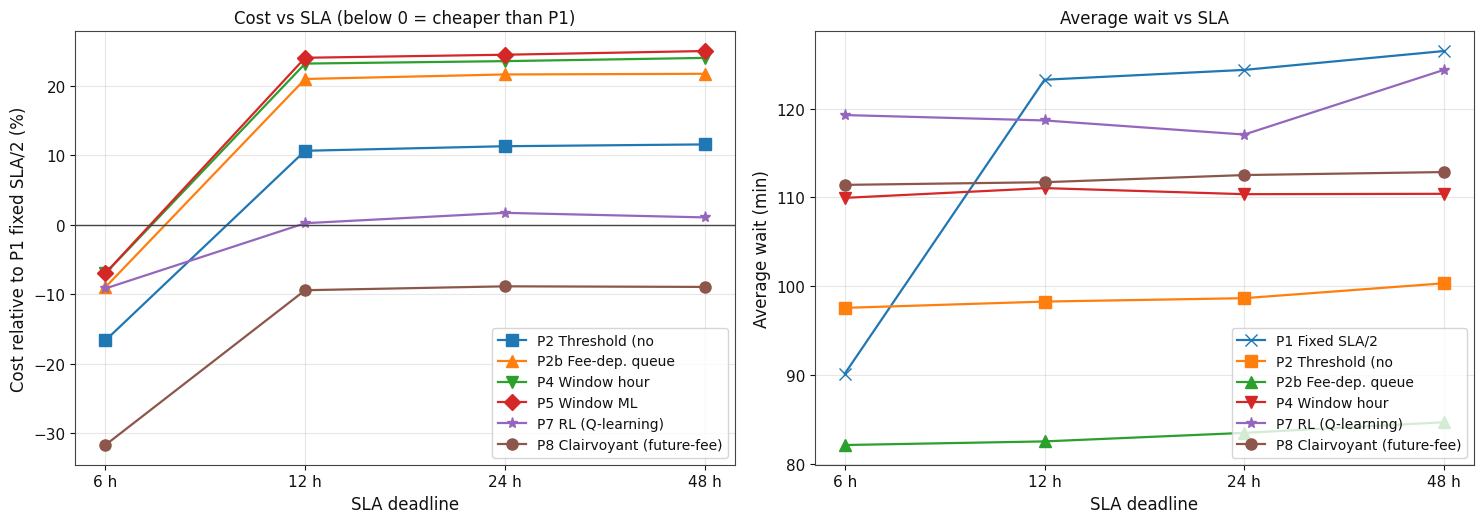

In [21]:
POLS = ["P1 Fixed SLA/2", "P2 Threshold (no ML)", "P2b Fee-dep. queue threshold", "P3 Window random", "P4 Window hour prior", "P5 Window ML",
        "P6 Window oracle label", "P7 RL (Q-learning)", "P8 Clairvoyant (future-fee)"]
pol_tbl = sla_df.groupby(["sla_h", "policy"]).agg(cost_eth=("cost_eth", "mean"), reduction_pct=("reduction_pct", "mean"), avg_wait_min=("avg_wait_min", "mean"),
                                                    min_sla_pct=("sla_pct", "min"), transactions=("transactions", "mean")).reset_index()
pol_tbl.to_csv(ART / "sla_sensitivity_policies.csv", index=False)
print("Cost reduction vs immediate anchoring (%), by SLA:"); display(pol_tbl.pivot(index="policy", columns="sla_h", values="reduction_pct").reindex(POLS).round(2))
print("Average wait (min), by SLA:"); display(pol_tbl.pivot(index="policy", columns="sla_h", values="avg_wait_min").reindex(POLS).round(1))
print("Total modelled cost (ETH), by SLA:"); display(pol_tbl.pivot(index="policy", columns="sla_h", values="cost_eth").reindex(POLS).round(4))

def sla_pair(h, pa, pb, B=5000):
    m = sla_df[sla_df.sla_h == h]
    a = m[m.policy == pa].groupby(["fold", "seed"])[["cost_eth", "avg_wait_min"]].mean(); b = m[m.policy == pb].groupby(["fold", "seed"])[["cost_eth", "avg_wait_min"]].mean()
    if a.empty or b.empty: return None
    d = (100 * (a.cost_eth / b.cost_eth - 1)).groupby("fold").mean().values; dw = (a.avg_wait_min - b.avg_wait_min).groupby("fold").mean().values
    lo_, hi_ = boot_ci(d, B); return d.mean(), lo_, hi_, dw.mean()
fmt = lambda r: "n/a" if r is None else f"{r[0]:+.1f}% [{r[1]:+.1f}, {r[2]:+.1f}], wait {r[3]:+.1f} min"

num, shown = [], []
for h in SLA_SENS_HOURS:
    g = pol_tbl[pol_tbl.sla_h == h].set_index("policy"); real = g.drop(index=[p for p in ["P0 Immediate", "P8 Clairvoyant (future-fee)"] if p in g.index])
    best = real.reduction_pct.idxmax(); gap = float(g.loc["P8 Clairvoyant (future-fee)", "reduction_pct"] - real.reduction_pct.max())
    gx = g.drop(index="P0 Immediate", errors="ignore")          # P0 is the 0 % reference, so it is excluded from the reduction range
    num.append({"sla_h": h, "min reduction %": gx.reduction_pct.min(), "max reduction %": gx.reduction_pct.max(), "P8 gap (pp)": gap, "best realistic (cost)": real.cost_eth.idxmin()})
    shown.append({"SLA (h)": h, "reduction range (%)": f"{gx.reduction_pct.min():.2f}-{gx.reduction_pct.max():.2f}", "P8 gap over best realistic (pp)": round(gap, 2),
                  "cheapest realistic policy": real.cost_eth.idxmin().split(" ")[0], "P2b vs P1": fmt(sla_pair(h, "P2b Fee-dep. queue threshold", "P1 Fixed SLA/2")),
                  "P7 (RL) vs P1": fmt(sla_pair(h, "P7 RL (Q-learning)", "P1 Fixed SLA/2")) if SLA_SENS_RL else "not run",
                  "P5 (ML) vs P4": fmt(sla_pair(h, "P5 Window ML", "P4 Window hour prior")), "min SLA compliance (%)": float(g.min_sla_pct.min())})
sla_sum = pd.DataFrame(num); sla_show = pd.DataFrame(shown); display(sla_show)
sla_show.to_csv(ART / "sla_sensitivity_summary.csv", index=False)
try: sla_show.to_latex(ART / "table_sla_sensitivity.tex", index=False)
except Exception as e: print("LaTeX export skipped:", type(e).__name__)
print("Cost differences are fold-paired (mean of per-fold % differences, 95% bootstrap CI over folds; negative = first policy cheaper). Read cost together with wait.")
print("Caveat: window policies (P3-P6) keep 6-h windows and a 24-h horizon. At SLA <= 12 h later windows are unreachable, so they are limited by the guard and the",
      "P5-vs-P4 comparison there is not informative; at 48 h they are unchanged (they never wait past 24 h).")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.4), facecolor="white")
xs = list(range(len(SLA_SENS_HOURS)))
for p, mk in zip(["P2 Threshold (no ML)", "P2b Fee-dep. queue threshold", "P4 Window hour prior", "P5 Window ML", "P7 RL (Q-learning)", "P8 Clairvoyant (future-fee)"], ["s", "^", "v", "D", "*", "o"]):
    ys = []
    for h in SLA_SENS_HOURS:
        g = pol_tbl[pol_tbl.sla_h == h].set_index("policy")
        ys.append(100 * (g.loc[p, "cost_eth"] / g.loc["P1 Fixed SLA/2", "cost_eth"] - 1) if p in g.index else np.nan)
    axes[0].plot(xs, ys, marker=mk, ms=8, lw=1.6, label=p.split(" ")[0] + " " + " ".join(p.split(" ")[1:3]))
axes[0].axhline(0, color="#444", lw=1); axes[0].set_xticks(xs); axes[0].set_xticklabels([f"{h} h" for h in SLA_SENS_HOURS]); axes[0].set_xlabel("SLA deadline")
axes[0].set_ylabel("Cost relative to P1 fixed SLA/2 (%)"); axes[0].set_title("Cost vs SLA (below 0 = cheaper than P1)"); axes[0].grid(alpha=.3); axes[0].legend(fontsize=10)
for p, mk in zip(["P1 Fixed SLA/2", "P2 Threshold (no ML)", "P2b Fee-dep. queue threshold", "P4 Window hour prior", "P7 RL (Q-learning)", "P8 Clairvoyant (future-fee)"], ["x", "s", "^", "v", "*", "o"]):
    ys = [pol_tbl[(pol_tbl.sla_h == h) & (pol_tbl.policy == p)].avg_wait_min.mean() for h in SLA_SENS_HOURS]
    axes[1].plot(xs, ys, marker=mk, ms=8, lw=1.6, label=p.split(" ")[0] + " " + " ".join(p.split(" ")[1:3]))
axes[1].set_xticks(xs); axes[1].set_xticklabels([f"{h} h" for h in SLA_SENS_HOURS]); axes[1].set_xlabel("SLA deadline"); axes[1].set_ylabel("Average wait (min)")
axes[1].set_title("Average wait vs SLA"); axes[1].grid(alpha=.3); axes[1].legend(fontsize=10)
plt.tight_layout(); fig.savefig(ART / "fig_sla_sensitivity.png", dpi=300, bbox_inches="tight"); plt.show()

## 7i. [v11] Slack-aware timing: how much of the clairvoyant headroom can a deadline-aware rule or an ML forecast capture?

**Why.** Sections 5 to 7h show that batching gives almost all of the saving, that the window classifier does not beat the hour-of-day prior, and that tabular Q-learning does not beat a tuned threshold. P8 is still noticeably cheaper than the realistic policies on the cost that remains after batching. Two things stand out:

1. P2 and P2b use the same fee threshold whether the oldest certificate has 23 h or 1 h left; the deadline only matters through the last-30-minute guard. Stopping theory says the acceptable fee should rise as the deadline nears.
2. The window classifier predicts "which 6 h window is cheapest", which the P6 result shows is a poor match for the cost a trigger achieves. A better target is what the decision depends on: how much cheaper than now will the best fee before the deadline be?

**New policies** (all keep the SLA guard and full-queue override, so compliance is guaranteed by design):

| ID | Policy | Learned? |
|---|---|---|
| P2p | static percentile threshold; percentile and `min_batch` tuned on validation (the control for P9) | no |
| **P9** | **slack-ramp**: anchor when fee ≤ rolling percentile `p(u) = p_lo + (p_hi - p_lo) * u^k`, where `u` = age of the oldest pending certificate / SLA. P2 is the case `p_lo = p_hi = 20 %`. | no (3 tuned parameters) |
| P10p | **wait-value trigger, hour prior**: predicted value of waiting = median of `y_H` by hour of day over the training data | no |
| **P10** | **wait-value trigger, ML**: gradient-boosted median regression of `y_H = log(min fee over next H steps / current fee)` for H = 1, 3, 6, 12, 24 h, using the smallest H that covers the remaining slack. Anchor when the predicted saving from waiting is at most a margin `m`. | yes |
| P10o | same trigger with the true `y_H` (not deployable); the ceiling for this family | oracle |

**Protocol (same as 7f-2).** Percentiles, ramp shape, margin `m` and `min_batch` are all chosen on the 60-day validation block under a wait budget, then scored once per test fold. The wait-value models train only on rows whose 24 h look-ahead ends before the validation block. Questions, each with a fold-paired bootstrap CI:

- **Slack-awareness alone:** P9 vs P2p.
- **ML forecast vs calendar:** P10 vs P10p, plus forecast MAE per horizon.
- **ML on top of slack-awareness:** P10 vs P9.
- **Against the best static rule and RL:** P9 and P10 vs the best of P1/P2/P2b/P2p, and P10 vs P7.
- **Equal wait:** each family runs along a grid of validation wait budgets (selection still on validation only), costs are interpolated at the same test wait, and paired differences are bootstrapped over folds. This stops a policy from looking cheaper only because it waits longer. P10o against the best static rule shows how much headroom the trigger family has.

**Reading the outcome.** If P9 wins and P10 adds nothing, the gain is deadline-awareness, not learning. If P10 beats P9, the decision-aligned target is what makes ML useful. If neither beats the best static rule, the negative result extends to decision-aligned ML. P9 and P10 search larger candidate pools than the rules, so P2p is the fair control for P9.

**Runtime:** about 260 candidate settings per fold and workload on validation. The 3-seed test runs only cover settings a validation-only rule can pick, so the section stays quick even with 20 monthly folds.

**[v12] Two additions:** 7i-1b measures how much the forecaster changes with the random seed, and 7i-5 plots cost against wait fold by fold.

In [22]:
# [v11] 7i-1  Inputs for P9 (slack ramp) and P10 (ML wait-value trigger).
# Nothing looks ahead: each model is trained on rows whose targets (<= 24 h ahead) end BEFORE the validation block, exactly like the RL agent,
# and the same model then serves the validation block (to tune the margin) and the test fold.
from sklearn.ensemble import HistGradientBoostingRegressor

THR_GRID = np.vstack([fser.rolling(THR_LOOKBACK).quantile(float(p)).values for p in PGRID])     # causal rolling percentiles, one row per level
_gi = int(round((PCTL - PGRID[0]) / 0.05))
assert abs(PGRID[_gi] - PCTL) < 1e-9 and np.array_equal(THR_GRID[_gi], thr, equal_nan=True), "grid level PCTL must reproduce the P2 threshold"

YARR = []        # YARR[i][t] = log(min fee over steps t+1..t+HZ[i] / fee[t]); below 0 means a cheaper moment is coming (the "value of waiting")
for H in HZ:
    fut_min = fser.rolling(H).min().shift(-H).values
    YARR.append(np.log((fut_min + EPS) / (fee + EPS)).astype(np.float32))

WV, skill_rows = {}, []
for fi, f in enumerate(fold_data):
    lo, hi = f["lo"], f["hi"]; val_lo = lo - VAL_DAYS * 288 - SLA_STEPS
    tr_end = val_lo - max(HZ)                                           # rows t < tr_end have targets ending before val_lo
    rows_ = np.arange(N); rows_ = rows_[(rows_ < tr_end) & feat_ok & (rows_ % WV_TRAIN_STRIDE == 0)]
    ev = np.arange(val_lo, hi); ev = ev[feat_ok[ev]]                    # steps where a prediction is needed (validation block + test fold)
    ml, prior = [], []
    for i, H in enumerate(HZ):
        y = YARR[i]; tr = rows_[np.isfinite(y[rows_])]
        assert len(tr) > 1000 and tr.max() + H < val_lo, "wait-value training window problem"
        mdl = HistGradientBoostingRegressor(loss="quantile", quantile=0.5, max_depth=3, learning_rate=0.05, max_iter=150, random_state=SEED).fit(X_all[tr], y[tr])
        pm = np.full(N, np.nan, np.float32); pm[ev] = mdl.predict(X_all[ev])
        hp = pd.Series(y[tr]).groupby(hour_all[tr]).median()
        pp = np.full(N, np.nan, np.float32); pp[ev] = pd.Series(hour_all[ev]).map(hp).fillna(float(np.median(y[tr]))).values
        ml.append(pm); prior.append(pp)
        te = ev[(ev >= lo) & np.isfinite(y[ev])]
        skill_rows.append(dict(fold=f["fs"], horizon_h=H * STEP_MIN / 60, mae_ml=float(np.abs(pm[te] - y[te]).mean()), mae_hour_prior=float(np.abs(pp[te] - y[te]).mean())))
    WV[fi] = dict(ml=ml, prior=prior, train_end=int(tr_end), val_lo=int(val_lo))
    print(f"fold {f['fs']}: wait-value models trained on rows up to step {tr_end:,} (validation starts at {val_lo:,})")

wv_skill = pd.DataFrame(skill_rows); wv_skill["ml_better"] = wv_skill.mae_ml < wv_skill.mae_hour_prior
wv_skill["skill_pct"] = 100 * (1 - wv_skill.mae_ml / wv_skill.mae_hour_prior)
sk = wv_skill.groupby("horizon_h").agg(mae_ml=("mae_ml", "mean"), mae_hour_prior=("mae_hour_prior", "mean"), folds_ml_better=("ml_better", "sum"), folds=("fold", "count")).reset_index()
sk["skill_vs_hour_prior_pct"] = 100 * (1 - sk.mae_ml / sk.mae_hour_prior)
ci_ = [boot_ci(g.skill_pct.values) for _, g in wv_skill.groupby("horizon_h")]
sk["skill 95% CI (folds)"] = [f"[{a:+.1f}, {b:+.1f}]" for a, b in ci_]
wv_skill_summary = sk
print("Forecast accuracy of the value of waiting on the TEST folds (MAE of log-ratio; skill > 0 = ML closer than the hour-of-day prior):")
display(sk.round(4)); sk.to_csv(ART / "v11_wait_value_forecast_skill.csv", index=False); wv_skill.to_csv(ART / "v11_wait_value_forecast_skill_by_fold.csv", index=False)


fold 2025-01-01: wait-value models trained on rows up to step 87,552 (validation starts at 87,840)
fold 2025-02-01: wait-value models trained on rows up to step 96,480 (validation starts at 96,768)
fold 2025-03-01: wait-value models trained on rows up to step 104,544 (validation starts at 104,832)
fold 2025-04-01: wait-value models trained on rows up to step 113,472 (validation starts at 113,760)
fold 2025-05-01: wait-value models trained on rows up to step 122,112 (validation starts at 122,400)
fold 2025-06-01: wait-value models trained on rows up to step 131,040 (validation starts at 131,328)
fold 2025-07-01: wait-value models trained on rows up to step 139,680 (validation starts at 139,968)
fold 2025-08-01: wait-value models trained on rows up to step 148,608 (validation starts at 148,896)
fold 2025-09-01: wait-value models trained on rows up to step 157,536 (validation starts at 157,824)
fold 2025-10-01: wait-value models trained on rows up to step 166,176 (validation starts at 166

,horizon_h,mae_ml,mae_hour_prior,folds_ml_better,folds,skill_vs_hour_prior_pct,skill 95% CI (folds)
0,1.0,0.1632,0.1984,20,20,17.7548,"[+15.4, +19.3]"
1,3.0,0.2021,0.2871,20,20,29.6204,"[+26.8, +31.7]"
2,6.0,0.2248,0.3597,20,20,37.5137,"[+34.9, +39.7]"
3,12.0,0.2460,0.4299,20,20,42.7673,"[+40.5, +45.0]"
4,24.0,0.2750,0.4837,20,20,43.1487,"[+40.4, +45.8]"


#### 7i-1b. [v12] Does the forecaster depend on the random seed?
The P10 model is retrained with four more seeds (`WV_SEEDS`; the original run used `SEED`). Gradient boosting here uses early stopping on a random validation split, so the seed does change the model. The table reports the pooled test-fold skill over the hour-of-day prior for each seed, with the spread across seeds. This only touches the forecaster; the downstream P9/P10 cost sweeps are not rerun.

In [23]:
# [v12] 7i-1b  Seed variance of the wait-value forecaster (same training rows, targets and test rows as 7i-1; only random_state changes).
WV_SEEDS = [1, 2, 3, 4]                                    # plus the SEED already used in 7i-1
seed_rows = []
for s in WV_SEEDS:
    for fi, f in enumerate(fold_data):
        lo, hi = f["lo"], f["hi"]; val_lo, tr_end = WV[fi]["val_lo"], WV[fi]["train_end"]
        rows_ = np.arange(N); rows_ = rows_[(rows_ < tr_end) & feat_ok & (rows_ % WV_TRAIN_STRIDE == 0)]
        ev = np.arange(val_lo, hi); ev = ev[feat_ok[ev]]
        for i, H in enumerate(HZ):
            y = YARR[i]; tr = rows_[np.isfinite(y[rows_])]
            mdl = HistGradientBoostingRegressor(loss="quantile", quantile=0.5, max_depth=3, learning_rate=0.05, max_iter=150, random_state=s).fit(X_all[tr], y[tr])
            te = ev[(ev >= lo) & np.isfinite(y[ev])]
            seed_rows.append(dict(seed=s, fold=f["fs"], horizon_h=H * STEP_MIN / 60, mae_ml=float(np.abs(mdl.predict(X_all[te]) - y[te]).mean())))
    print(f"seed {s} done ({time.time() - NB_T0:,.0f} s since start)")
base = wv_skill[["fold", "horizon_h", "mae_ml", "mae_hour_prior"]].copy(); base["seed"] = SEED
sv = pd.DataFrame(seed_rows).merge(wv_skill[["fold", "horizon_h", "mae_hour_prior"]], on=["fold", "horizon_h"])
sv = pd.concat([base[["seed", "fold", "horizon_h", "mae_ml", "mae_hour_prior"]], sv[["seed", "fold", "horizon_h", "mae_ml", "mae_hour_prior"]]], ignore_index=True)
sv.to_csv(ART / "v12_wait_value_seed_by_fold.csv", index=False)
per_seed = sv.groupby(["horizon_h", "seed"]).agg(mae_ml=("mae_ml", "mean"), mae_prior=("mae_hour_prior", "mean")).reset_index()
per_seed["skill_pct"] = 100 * (1 - per_seed.mae_ml / per_seed.mae_prior)
seed_var = per_seed.groupby("horizon_h").agg(skill_mean_pct=("skill_pct", "mean"), skill_sd_pct=("skill_pct", "std"), skill_min_pct=("skill_pct", "min"),
                                              skill_max_pct=("skill_pct", "max"), mae_ml_mean=("mae_ml", "mean"), mae_ml_sd=("mae_ml", "std"), n_seeds=("seed", "nunique")).reset_index()
print(f"Forecast skill over the hour-of-day prior across {1 + len(WV_SEEDS)} seeds (pooled over the {len(fold_data)} test folds):")
display(seed_var.round(4)); seed_var.to_csv(ART / "v12_wait_value_seed_variance.csv", index=False)

seed 1 done (4,065 s since start)
seed 2 done (4,149 s since start)
seed 3 done (4,233 s since start)
seed 4 done (4,317 s since start)
Forecast skill over the hour-of-day prior across 5 seeds (pooled over the 20 test folds):


,horizon_h,skill_mean_pct,skill_sd_pct,skill_min_pct,skill_max_pct,mae_ml_mean,mae_ml_sd,n_seeds
0,1.0,17.8141,0.0623,17.7530,17.8843,0.1630,0.0001,5
1,3.0,29.6912,0.0678,29.6204,29.7779,0.2019,0.0002,5
2,6.0,37.5356,0.0563,37.4562,37.6099,0.2247,0.0002,5
3,12.0,42.8025,0.0850,42.7011,42.8946,0.2459,0.0004,5
4,24.0,43.0459,0.0907,42.9551,43.1487,0.2755,0.0004,5


In [24]:
# [v11] 7i-2  Candidate sweep for P2p, P9, P10p, P10, P10o on the SAME workloads, arrival draws and validation/test blocks as section 7f.
# Runtime saver: every candidate is run on the validation block first; the (3-seed) test runs are done only for candidates that the validation-only
# rule would pick for at least one wait budget of the budget grid. All other candidates are never selected, so their test cost is not needed.
FAM_P2P, FAM_P9, FAM_P10P, FAM_P10, FAM_P10O = ("P2p static pctl (tuned)", "P9 slack-ramp", "P10p wait-value (hour prior)",
                                                 "P10 wait-value (ML)", "P10o wait-value (oracle, not deployable)")
for _k, _b in WAIT_BUDGETS.items(): assert set(_b) <= set(V11_BUDGET_GRID[_k]), f"V11_BUDGET_GRID must contain WAIT_BUDGETS for {_k}"
def v11_cands(fi, cap):
    """All (family, setting, scheduler config, min_batch) candidates for fold index fi."""
    out, mbs = [], [m for m in V11_MINB if m <= cap]
    for p in [0.10, 0.20, 0.30, 0.50, 0.80]:                                   # static percentile = ramp with p_lo = p_hi
        for m_ in mbs: out.append((FAM_P2P, f"p={p:g},mb={m_}", dict(mode="ramp", aux=dict(grid=THR_GRID, p_lo=p, p_hi=p, k=1)), m_))
    for plo in RAMP_PLO:
        for phi in RAMP_PHI:
            for k in RAMP_K:
                for m_ in mbs: out.append((FAM_P9, f"p{plo:g}->{phi:g},k={k},mb={m_}", dict(mode="ramp", aux=dict(grid=THR_GRID, p_lo=plo, p_hi=phi, k=k)), m_))
    for fam, pred in [(FAM_P10P, WV[fi]["prior"]), (FAM_P10, WV[fi]["ml"]), (FAM_P10O, YARR)]:
        for mg in WV_MARGINS:
            for m_ in mbs: out.append((fam, f"m={mg:g},mb={m_}", dict(mode="wv", aux=dict(pred=pred, m=mg)), m_))
    return out

def sweep_v11(wname, spec):
    rate, cap, gen, mkrng, kind = spec["rate"], spec["cap"], spec["gen"], spec["rng"], spec["kind"]; reps = spec.get("reps", SEEDS_SWEEP); rows = []; t0 = time.time()
    for fi, f in enumerate(fold_data):
        lo, hi = f["lo"], f["hi"]; last = hi - SLA_STEPS - 1
        val_lo, val_hi = lo - VAL_DAYS * 288 - SLA_STEPS, lo - SLA_STEPS
        assert val_hi + SLA_STEPS <= lo and val_lo > THR_LOOKBACK and WV[fi]["val_lo"] == val_lo, "validation block must end before the fold"
        varr = gen(mkrng(fi, 7), val_lo, val_hi - SLA_STEPS - 1); tarr = [gen(mkrng(fi, sd), lo, last) for sd in reps]      # identical draws to section 7f
        c0 = float(np.mean([evaluate_immediate(a, fee)["cost_eth"] for a in tarr]))
        cl = v11_cands(fi, cap); vr = [_run(varr, cfg, cap, mbx, val_lo, val_hi) for _, _, cfg, mbx in cl]                     # stage 1: validation only
        d = pd.DataFrame({"family": [c[0] for c in cl], "setting": [c[1] for c in cl], "val_cost": [v["cost_eth"] for v in vr], "val_wait": [v["avg_wait_min"] for v in vr]})
        need = {(fam, pick(g.reset_index(drop=True), W).setting) for fam, g in d.groupby("family") for W in V11_BUDGET_GRID[kind]}
        for (fam, setting, cfg, mbx), v in zip(cl, vr):                                                                          # stage 2: test runs for selectable candidates
            row = {"workload": wname, "fold": f["fs"], "family": fam, "setting": setting, "rl_seed": -1, "delay": np.nan, "val_cost": v["cost_eth"], "val_wait": v["avg_wait_min"],
                   "test_cost": np.nan, "test_wait": np.nan, "test_tx": np.nan, "test_cost_immediate": c0}
            if (fam, setting) in need:
                tr = [_run(a, cfg, cap, mbx, lo, hi) for a in tarr]
                row.update(test_cost=float(np.mean([r["cost_eth"] for r in tr])), test_wait=float(np.mean([r["avg_wait_min"] for r in tr])), test_tx=float(np.mean([r["transactions"] for r in tr])))
            rows.append(row)
        print(f"  [{wname}] fold {f['fs']} done ({time.time() - t0:.0f}s)")
    return pd.DataFrame(rows)

cand_v11 = pd.concat([sweep_v11(n, s) for n, s in WORKLOADS.items()], ignore_index=True)
cand_v11.to_csv(ART / "v11_candidates.csv", index=False)
print(f"{len(cand_v11):,} candidates evaluated on validation, {int(cand_v11.test_cost.notna().sum()):,} of them also on test (the only ones a validation-only rule can select)")


  [poisson 1.0/step] fold 2025-01-01 done (18s)
  [poisson 1.0/step] fold 2025-02-01 done (35s)
  [poisson 1.0/step] fold 2025-03-01 done (52s)
  [poisson 1.0/step] fold 2025-04-01 done (68s)
  [poisson 1.0/step] fold 2025-05-01 done (85s)
  [poisson 1.0/step] fold 2025-06-01 done (102s)
  [poisson 1.0/step] fold 2025-07-01 done (119s)
  [poisson 1.0/step] fold 2025-08-01 done (135s)
  [poisson 1.0/step] fold 2025-09-01 done (154s)
  [poisson 1.0/step] fold 2025-10-01 done (170s)
  [poisson 1.0/step] fold 2025-11-01 done (186s)
  [poisson 1.0/step] fold 2025-12-01 done (202s)
  [poisson 1.0/step] fold 2026-01-01 done (220s)
  [poisson 1.0/step] fold 2026-02-01 done (237s)
  [poisson 1.0/step] fold 2026-03-01 done (253s)
  [poisson 1.0/step] fold 2026-04-01 done (269s)
  [poisson 1.0/step] fold 2026-05-01 done (285s)
  [poisson 1.0/step] fold 2026-06-01 done (302s)
  [poisson 1.0/step] fold 2026-07-01 done (318s)
  [poisson 1.0/step] fold 2026-08-01 done (335s)
  [bursty 0.2/step + burs

In [25]:
# [v11] 7i-3  Matched-budget comparison (settings chosen on VALIDATION only) and fold-paired CIs.
cand_all = pd.concat([cand, cand_v11], ignore_index=True)
FAM_STATIC = ["P1 fixed interval", "P2 threshold", "P2b fee-dep. queue", FAM_P2P]
FAM_V11 = FAM_STATIC + [FAM_P9, FAM_P10P, FAM_P10, "P7 RL", FAM_P10O]

rows = []
for wname, spec in WORKLOADS.items():
    for W in WAIT_BUDGETS[spec["kind"]]:
        for fam in FAM_V11:
            for fold, g in cand_all[(cand_all.workload == wname) & (cand_all.family == fam)].groupby("fold"):
                p = pick(g.reset_index(drop=True), W)
                rows.append({"workload": wname, "budget_min": W, "family": fam, "fold": fold, "chosen_setting": p.setting, "feasible_on_val": bool((g.val_wait <= W).any()),
                             "val_wait": p.val_wait, "test_cost": p.test_cost, "test_wait": p.test_wait})
v11_mb = pd.DataFrame(rows); v11_mb.to_csv(ART / "v11_matched_budget_by_fold.csv", index=False)

sum_rows, pair_rows = [], []
PAIRS = [(FAM_P9, FAM_P2P, "P9 vs P2p", "slack-awareness alone"),
         (FAM_P9, "best static", "P9 vs best static rule", "P9 against the best of P1/P2/P2b/P2p"),
         (FAM_P10, FAM_P10P, "P10 vs P10p", "ML forecast vs hour-of-day forecast"),
         (FAM_P10, FAM_P9, "P10 vs P9", "ML on top of slack-awareness"),
         (FAM_P10, "best static", "P10 vs best static rule", "P10 against the best of P1/P2/P2b/P2p"),
         (FAM_P10, "P7 RL", "P10 vs P7 RL", "decision-aligned ML vs tabular RL"),
         (FAM_P10O, "best static", "P10o vs best static rule", "ceiling of the trigger family (true value of waiting)")]
for (w, W), g in v11_mb.groupby(["workload", "budget_min"], sort=False):
    cost = g.pivot(index="fold", columns="family", values="test_cost"); wait = g.pivot(index="fold", columns="family", values="test_wait")
    for fam in FAM_V11:
        sum_rows.append({"workload": w, "budget_min": W, "family": fam, "test_cost_eth": cost[fam].mean(), "test_wait_min": wait[fam].mean(),
                         "folds_feasible_on_val": int(g[g.family == fam].feasible_on_val.sum()), "folds": len(cost)})
    best = min(FAM_STATIC, key=lambda x: cost[x].mean()); cost["best static"], wait["best static"] = cost[best], wait[best]
    for a, b, key, text in PAIRS:
        d = 100 * (cost[a] / cost[b] - 1).values; dw = (wait[a] - wait[b]).values; lo_, hi_ = boot_ci(d)
        pair_rows.append({"workload": w, "budget_min": W, "pair": key, "meaning": text, "B is": best if b == "best static" else b, "cost diff % (A vs B)": round(d.mean(), 2),
                          "95% CI (folds)": f"[{lo_:+.1f}, {hi_:+.1f}]", "A cheaper in folds": f"{int((d < 0).sum())}/{len(d)}", "wait diff (min)": round(dw.mean(), 1)})
v11_mb_summary = pd.DataFrame(sum_rows); v11_pairs = pd.DataFrame(pair_rows)
v11_mb_summary.to_csv(ART / "v11_matched_budget_summary.csv", index=False); v11_pairs.to_csv(ART / "v11_paired_comparisons.csv", index=False)
print("Matched-budget test cost (ETH) and wait (min), mean over folds; every setting chosen on VALIDATION data only:")
display(v11_mb_summary.round(4))
print("\nFold-paired comparisons at the same VALIDATION wait budget (negative = A cheaper; CI = 95% bootstrap over folds). Test waits still differ between policies,")
print("so read 'wait diff' and use the equal-wait comparison in the next cell for the final statements.")
display(v11_pairs)
print("Caveat: P9/P10 have larger candidate pools (72 / 42 settings) than P1/P2/P2b (7-11) and P2p (30); validation noise can hurt larger pools, so P2p is the matched control for P9.")


Matched-budget test cost (ETH) and wait (min), mean over folds; every setting chosen on VALIDATION data only:


,workload,budget_min,family,test_cost_eth,test_wait_min,folds_feasible_on_val,folds
0,poisson 1.0/step,80,P1 fixed interval,0.0466,59.7297,20,20
1,poisson 1.0/step,80,P2 threshold,0.0437,77.6216,20,20
2,poisson 1.0/step,80,P2b fee-dep. queue,0.0302,78.9876,20,20
3,poisson 1.0/step,80,P2p static pctl (tuned),0.0294,78.2283,20,20
4,poisson 1.0/step,80,P9 slack-ramp,0.0343,78.1244,20,20
5,poisson 1.0/step,80,P10p wait-value (hour prior),0.0330,80.8287,20,20
6,poisson 1.0/step,80,P10 wait-value (ML),0.0281,76.4712,20,20
7,poisson 1.0/step,80,P7 RL,0.0475,79.3771,12,20
8,poisson 1.0/step,80,"P10o wait-value (oracle, not deployable)",0.0274,76.4504,20,20
9,poisson 1.0/step,100,P1 fixed interval,0.0300,90.2012,20,20



Fold-paired comparisons at the same VALIDATION wait budget (negative = A cheaper; CI = 95% bootstrap over folds). Test waits still differ between policies,
so read 'wait diff' and use the equal-wait comparison in the next cell for the final statements.


,workload,budget_min,pair,meaning,B is,cost diff % (A vs B),95% CI (folds),A cheaper in folds,wait diff (min)
0,poisson 1.0/step,80,P9 vs P2p,slack-awareness alone,P2p static pctl (tuned),9.72,"[+2.7, +18.1]",6/20,-0.1
1,poisson 1.0/step,80,P9 vs best static rule,P9 against the best of P1/P2/P2b/P2p,P2p static pctl (tuned),9.72,"[+2.7, +18.1]",6/20,-0.1
2,poisson 1.0/step,80,P10 vs P10p,ML forecast vs hour-of-day forecast,P10p wait-value (hour prior),-9.55,"[-17.2, -1.9]",15/20,-4.4
3,poisson 1.0/step,80,P10 vs P9,ML on top of slack-awareness,P9 slack-ramp,-5.84,"[-14.3, +2.0]",12/20,-1.7
4,poisson 1.0/step,80,P10 vs best static rule,P10 against the best of P1/P2/P2b/P2p,P2p static pctl (tuned),1.56,"[-6.6, +10.2]",11/20,-1.8
5,poisson 1.0/step,80,P10 vs P7 RL,decision-aligned ML vs tabular RL,P7 RL,-27.10,"[-40.8, -13.3]",16/20,-2.9
6,poisson 1.0/step,80,P10o vs best static rule,ceiling of the trigger family (true value of w...,P2p static pctl (tuned),-0.80,"[-10.2, +10.8]",11/20,-1.8
7,poisson 1.0/step,100,P9 vs P2p,slack-awareness alone,P2p static pctl (tuned),-1.04,"[-4.7, +2.2]",10/20,-0.7
8,poisson 1.0/step,100,P9 vs best static rule,P9 against the best of P1/P2/P2b/P2p,P2p static pctl (tuned),-1.04,"[-4.7, +2.2]",10/20,-0.7
9,poisson 1.0/step,100,P10 vs P10p,ML forecast vs hour-of-day forecast,P10p wait-value (hour prior),-10.25,"[-14.6, -5.7]",18/20,-3.7


Caveat: P9/P10 have larger candidate pools (72 / 42 settings) than P1/P2/P2b (7-11) and P2p (30); validation noise can hurt larger pools, so P2p is the matched control for P9.


Equal-test-wait comparisons (negative = A cheaper at the same average wait; CI = 95% bootstrap over folds; only folds where both policies reach that wait are used):


,workload,equal_wait_min,pair,meaning,B is,cost diff % (A vs B),95% CI (folds),A cheaper in folds,folds used
0,poisson 1.0/step,80,P9 vs P2p,slack-awareness alone,P2p static pctl (tuned),9.40,"[+3.9, +15.8]",3/19,19
1,poisson 1.0/step,80,P9 vs best static rule,P9 against the best of P1/P2/P2b/P2p,P2p static pctl (tuned),9.40,"[+3.9, +15.8]",3/19,19
2,poisson 1.0/step,80,P10 vs P10p,ML forecast vs hour-of-day forecast,P10p wait-value (hour prior),-16.22,"[-20.5, -12.7]",20/20,20
3,poisson 1.0/step,80,P10 vs P9,ML on top of slack-awareness,P9 slack-ramp,-9.54,"[-14.2, -5.4]",17/19,19
4,poisson 1.0/step,80,P10 vs best static rule,P10 against the best of P1/P2/P2b/P2p,P2p static pctl (tuned),-2.19,"[-5.4, +0.8]",11/20,20
5,poisson 1.0/step,80,P10 vs P7 RL,decision-aligned ML vs tabular RL,P7 RL,-25.76,"[-38.3, -13.7]",8/9,9
6,poisson 1.0/step,80,P10o vs best static rule,ceiling of the trigger family (true value of w...,P2p static pctl (tuned),-6.04,"[-10.7, -2.4]",17/20,20
7,poisson 1.0/step,100,P9 vs P2p,slack-awareness alone,P2p static pctl (tuned),-1.37,"[-4.5, +1.3]",10/20,20
8,poisson 1.0/step,100,P9 vs best static rule,P9 against the best of P1/P2/P2b/P2p,P2p static pctl (tuned),-1.37,"[-4.5, +1.3]",10/20,20
9,poisson 1.0/step,100,P10 vs P10p,ML forecast vs hour-of-day forecast,P10p wait-value (hour prior),-12.00,"[-16.2, -8.2]",19/20,20


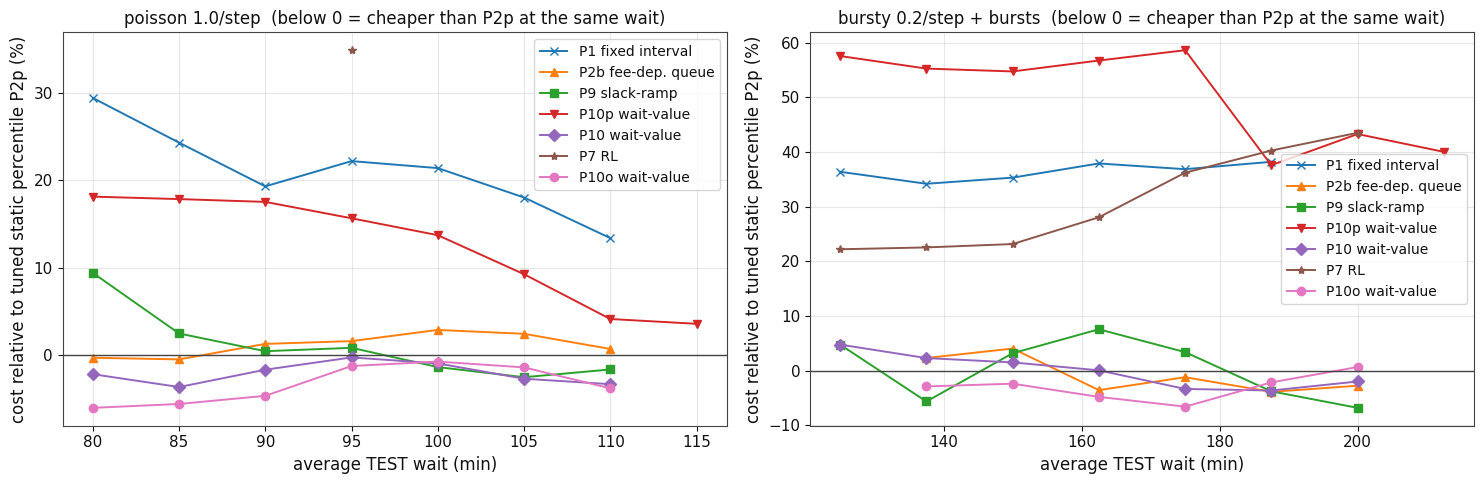

In [26]:
# [v11] 7i-4  Equal-wait comparison. Each family is run along a grid of validation wait budgets (settings still chosen on validation only); this gives
# per fold a cost-vs-TEST-wait curve per family. Costs are interpolated at the same test wait, so no policy can look cheaper just because it waits longer.
def interp_cost(pts, w):
    pts = sorted({p for p in pts if np.isfinite(p[0]) and np.isfinite(p[1])}); xs = np.array([p[0] for p in pts]); ys = np.array([p[1] for p in pts])
    return float(np.interp(w, xs, ys)) if len(xs) >= 2 and xs.min() <= w <= xs.max() else np.nan

curves = {}
for wname, spec in WORKLOADS.items():
    for fam in FAM_V11:
        for fold, g in cand_all[(cand_all.workload == wname) & (cand_all.family == fam)].groupby("fold"):
            g = g.reset_index(drop=True); curves[(wname, fold, fam)] = [(float(p.test_wait), float(p.test_cost)) for p in (pick(g, W) for W in V11_BUDGET_GRID[spec["kind"]])]
folds_ = [f["fs"] for f in fold_data]; ew_rows = []
for wname, spec in WORKLOADS.items():
    for W in WAIT_BUDGETS[spec["kind"]]:
        Cm = pd.DataFrame({fam: [interp_cost(curves[(wname, fo, fam)], W) for fo in folds_] for fam in FAM_V11}, index=folds_)
        st = Cm[FAM_STATIC].dropna()
        if len(st) < 3: continue
        best = st.mean().idxmin(); Cm["best static"] = Cm[best]
        for a, b, key, text in PAIRS:
            ok = Cm[a].notna() & Cm[b].notna()
            if ok.sum() < 3: continue
            d = 100 * (Cm.loc[ok, a] / Cm.loc[ok, b] - 1).values; lo_, hi_ = boot_ci(d)
            ew_rows.append({"workload": wname, "equal_wait_min": W, "pair": key, "meaning": text, "B is": best if b == "best static" else b, "cost diff % (A vs B)": round(d.mean(), 2),
                            "95% CI (folds)": f"[{lo_:+.1f}, {hi_:+.1f}]", "A cheaper in folds": f"{int((d < 0).sum())}/{len(d)}", "folds used": int(ok.sum()), "_lo": lo_, "_hi": hi_})
v11_ew_pairs = pd.DataFrame(ew_rows)
v11_ew_pairs.drop(columns=["_lo", "_hi"]).to_csv(ART / "v11_equal_wait_pairs.csv", index=False)
print("Equal-test-wait comparisons (negative = A cheaper at the same average wait; CI = 95% bootstrap over folds; only folds where both policies reach that wait are used):")
display(v11_ew_pairs.drop(columns=["_lo", "_hi"]))

fig, axes = plt.subplots(1, len(WORKLOADS), figsize=(7.5 * len(WORKLOADS), 5), facecolor="white", squeeze=False)
for ax, (wname, spec) in zip(axes[0], WORKLOADS.items()):
    grid_ = V11_BUDGET_GRID[spec["kind"]]; wg = np.linspace(grid_[1], grid_[-2], 9)
    for fam, mk in zip(["P1 fixed interval", "P2b fee-dep. queue", FAM_P9, FAM_P10P, FAM_P10, "P7 RL", FAM_P10O], ["x", "^", "s", "v", "D", "*", "o"]):
        ys = []
        for w in wg:
            r = [100 * (interp_cost(curves[(wname, fo, fam)], w) / interp_cost(curves[(wname, fo, FAM_P2P)], w) - 1) for fo in folds_]; r = [x for x in r if np.isfinite(x)]
            ys.append(np.mean(r) if len(r) >= 0.7 * len(folds_) else np.nan)
        ax.plot(wg, ys, marker=mk, ms=6, lw=1.4, label=fam.split(" (")[0])
    ax.axhline(0, color="#444", lw=1); ax.set_xlabel("average TEST wait (min)"); ax.set_ylabel("cost relative to tuned static percentile P2p (%)")
    ax.set_title(wname + "  (below 0 = cheaper than P2p at the same wait)"); ax.grid(alpha=.3); ax.legend(fontsize=10)
plt.tight_layout(); fig.savefig(ART / "fig_v11_equal_wait.png", dpi=300, bbox_inches="tight"); plt.show()


#### 7i-5. [v12] Fold-level cost against wait
One thin line per fold shows cost relative to the tuned static rule P2p at the same test wait. The bold line is the mean over folds, and points where fewer than half of the folds reach that wait are left out. If the thin lines scatter widely around the mean, the averages in 7i-4 hide fold-to-fold variation.

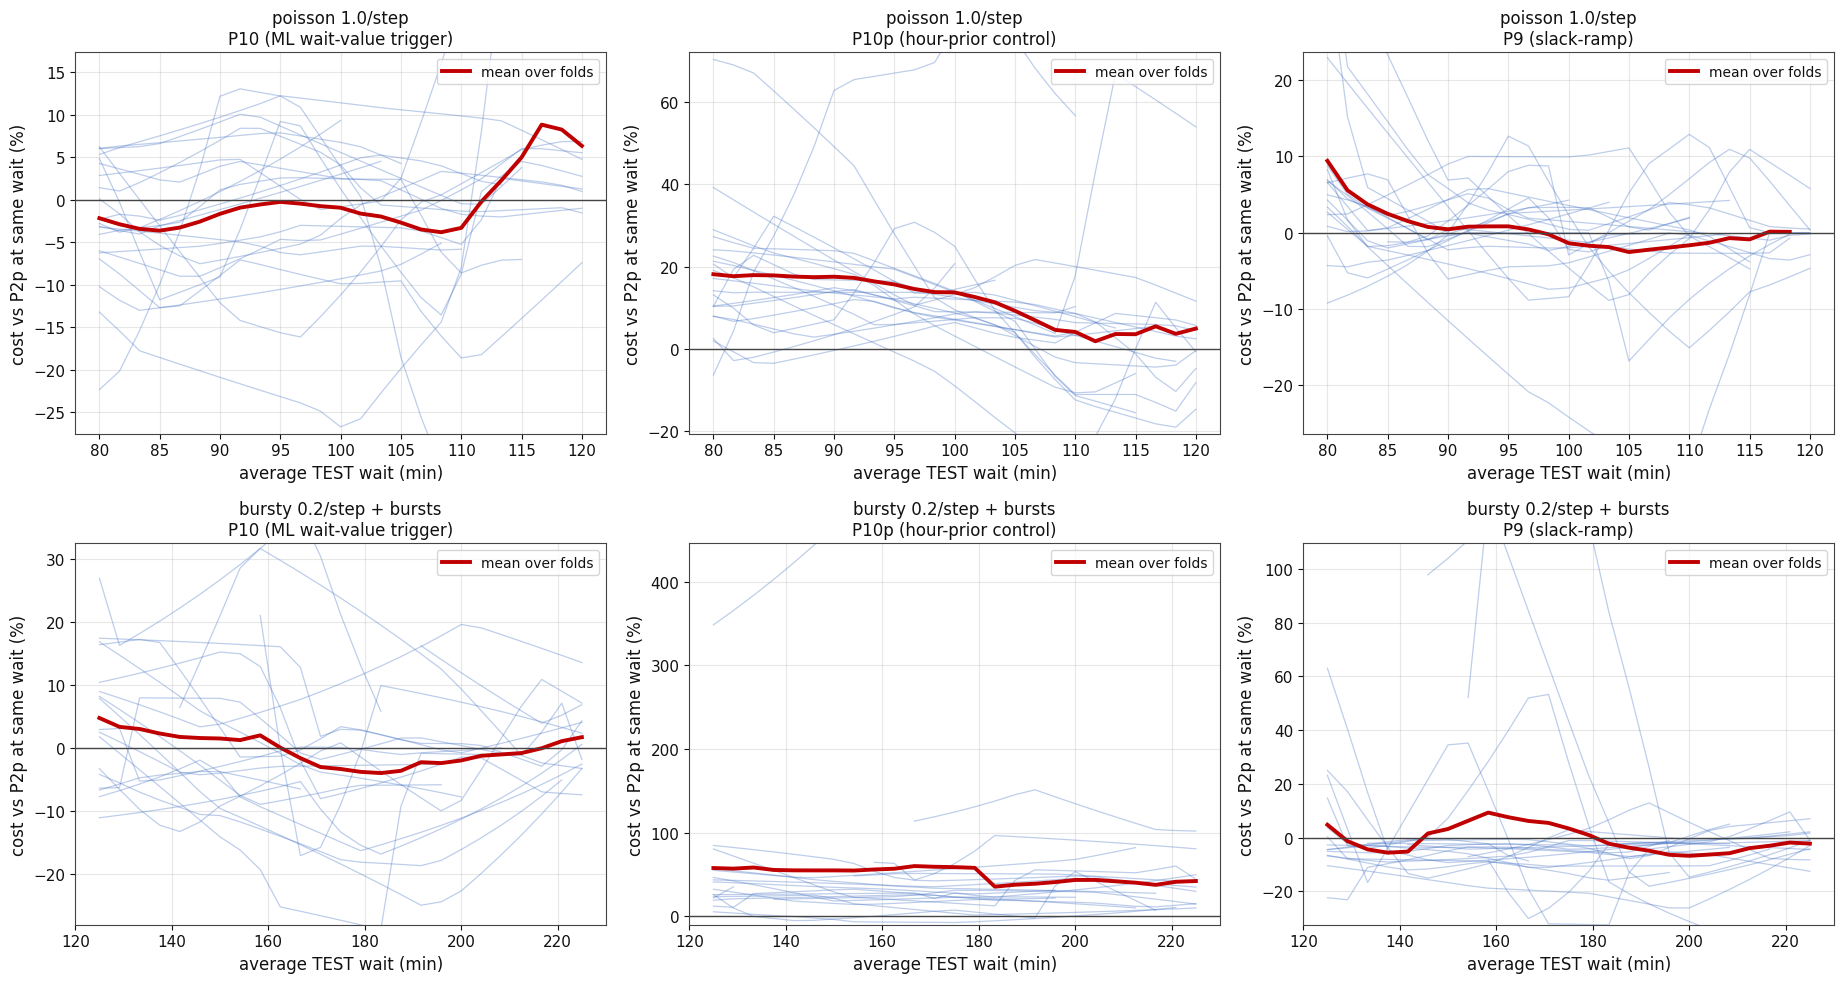

saved fold-level curves: 2561 points


In [27]:
# [v12] 7i-5  Fold-level cost-vs-wait curves (uses `curves` and `interp_cost` from 7i-4).
pf_fams = [(FAM_P10, "P10 (ML wait-value trigger)"), (FAM_P10P, "P10p (hour-prior control)"), (FAM_P9, "P9 (slack-ramp)")]
fig, axes = plt.subplots(len(WORKLOADS), len(pf_fams), figsize=(6.2 * len(pf_fams), 5.0 * len(WORKLOADS)), facecolor="white", squeeze=False)
pf_rows = []
for r, (wname, spec) in enumerate(WORKLOADS.items()):
    grid_ = V11_BUDGET_GRID[spec["kind"]]; wg = np.linspace(grid_[1], grid_[-2], 25)
    for c, (fam, title) in enumerate(pf_fams):
        ax = axes[r][c]; M = []
        for fo in folds_:
            y = []
            for w in wg:
                a, b = interp_cost(curves[(wname, fo, fam)], w), interp_cost(curves[(wname, fo, FAM_P2P)], w)
                y.append(100 * (a / b - 1) if np.isfinite(a) and np.isfinite(b) and b > 0 else np.nan)
            y = np.array(y, float); M.append(y); ax.plot(wg, y, lw=0.9, alpha=0.35, color="#4472c4")
            pf_rows += [dict(workload=wname, family=fam, fold=fo, test_wait_min=float(w), cost_vs_P2p_pct=float(v)) for w, v in zip(wg, y) if np.isfinite(v)]
        M = np.array(M); mean = np.nanmean(M, axis=0); mean[np.isfinite(M).sum(0) < 0.5 * len(folds_)] = np.nan
        ax.plot(wg, mean, lw=2.8, color="#c00000", label="mean over folds"); ax.axhline(0, color="#444", lw=1)
        fin = M[np.isfinite(M)]
        if fin.size: lo_, hi_ = np.percentile(fin, [2, 98]); ax.set_ylim(min(lo_, -5) - 5, max(hi_, 5) + 5)
        ax.set_title(f"{wname}\n{title}"); ax.set_xlabel("average TEST wait (min)"); ax.set_ylabel("cost vs P2p at same wait (%)"); ax.grid(alpha=.3); ax.legend(loc="upper right")
plt.tight_layout(); fig.savefig(ART / "fig_v12_cost_vs_wait_by_fold.png", dpi=300, bbox_inches="tight"); plt.show()
pd.DataFrame(pf_rows).to_csv(ART / "v12_cost_vs_wait_by_fold.csv", index=False)
print("saved fold-level curves:", len(pf_rows), "points")

In [28]:
# [v11] 7i-4  Self-tests for the new policies (these are in addition to the eight tests in section 11).
def check_inv(batches, arr, cap):
    assert sum(b - a for _, a, b in batches) == len(arr), "anchored count mismatch"
    assert all((b - a) <= cap for _, a, b in batches), "batch above cap"
    assert all(batches[i][2] == batches[i + 1][1] for i in range(len(batches) - 1)), "FIFO broken"
    assert max(t - arr[a] for t, a, b in batches) <= SLA_STEPS, "SLA breached"

# T9: P2 is the special case p_lo = p_hi = PCTL of the slack ramp (identical anchor times and batches)
f_ = fold_data[-1]; lo_, hi_ = f_["lo"], f_["hi"]; mb_ = min_batch_for(MAIN_RATE, MAIN_CAP)
arr_ = poisson_gen(MAIN_RATE)(np.random.default_rng(17), lo_, hi_ - SLA_STEPS - 1)
b2, _ = run_scheduler(fee, thr, thr2, arr_, mode="threshold", cap=MAIN_CAP, min_batch=mb_, start=lo_, end=hi_)
br, _ = run_scheduler(fee, thr, thr2, arr_, mode="ramp", cap=MAIN_CAP, min_batch=mb_, start=lo_, end=hi_, aux=dict(grid=THR_GRID, p_lo=PCTL, p_hi=PCTL, k=1))
assert b2 == br, "ramp with p_lo = p_hi = PCTL must reproduce P2"
print("T9 ok: slack ramp with a constant percentile reproduces P2 exactly")

# T10: no look-ahead into validation/test when training the wait-value models
for fi, f in enumerate(fold_data):
    assert (WV[fi]["train_end"] - 1) + max(HZ) < WV[fi]["val_lo"] and WV[fi]["val_lo"] == f["lo"] - VAL_DAYS * 288 - SLA_STEPS, "wait-value training targets reach into validation"
print("T10 ok: every wait-value model is trained on targets that end before its validation block")

# T11: scheduler invariants (once, FIFO, cap, SLA) for P9 / P10 / P10o on every fold and seed
n_chk = 0
for fi, f in enumerate(fold_data):
    lo, hi = f["lo"], f["hi"]
    for sd in SEEDS_SWEEP:
        arr = poisson_gen(MAIN_RATE)(np.random.default_rng(sd), lo, hi - SLA_STEPS - 1)
        for cfg in (dict(mode="ramp", aux=dict(grid=THR_GRID, p_lo=0.1, p_hi=0.8, k=3)), dict(mode="wv", aux=dict(pred=WV[fi]["ml"], m=0.25)),
                    dict(mode="wv", aux=dict(pred=WV[fi]["prior"], m=0.25)), dict(mode="wv", aux=dict(pred=YARR, m=0.25))):
            bt, left = run_scheduler(fee, thr, thr2, arr, cap=MAIN_CAP, min_batch=mb_, start=lo, end=hi, **cfg); assert left == 0; check_inv(bt, arr, MAIN_CAP); n_chk += 1
print(f"T11 ok: scheduler invariants hold in {n_chk} P9/P10 runs")

# T12: validation-only selection: blanking every test column does not change any chosen setting
blank = cand_all.copy(); blank[["test_cost", "test_wait", "test_tx"]] = np.nan; chg = 0
for wname, spec in WORKLOADS.items():
    for W in WAIT_BUDGETS[spec["kind"]]:
        for fam in [FAM_P9, FAM_P10, FAM_P10P, FAM_P2P]:
            for fold, g in cand_all[(cand_all.workload == wname) & (cand_all.family == fam)].groupby("fold"):
                a = pick(g.reset_index(drop=True), W).setting; b = pick(blank.loc[g.index].reset_index(drop=True), W).setting; chg += int(a != b)
assert chg == 0, "selection depends on test columns"
print("T12 ok: selection of P2p / P9 / P10p / P10 settings is unchanged when test columns are blanked")

# T13: the ML wait-value prediction at step t does not depend on fees after t (prediction row = causal feature row)
t_ = int(fold_data[-1]["lo"] + 5000); X2 = build_features(df.assign(avg_base_fee_gwei=np.where(np.arange(N) > t_, 1e3, df.avg_base_fee_gwei.values))).values.astype(float)
assert np.allclose(X2[t_], X_all[t_], equal_nan=True), "features at t changed when future fees changed"
print("T13 ok: features used by the wait-value model at step t are unchanged when all later fees are altered")

# T14: runtime saver is exact: re-running a stored (selectable) candidate on the test fold reproduces the stored test cost; unselected candidates carry no test value
_f0 = fold_data[-1]; _fi0 = len(fold_data) - 1; _spec = WORKLOADS[next(iter(WORKLOADS))]; _w0 = next(iter(WORKLOADS))
_rows = cand_v11[(cand_v11.workload == _w0) & (cand_v11.fold == _f0["fs"]) & cand_v11.test_cost.notna()]
_cl = {(c[0], c[1]): c for c in v11_cands(_fi0, _spec["cap"])}; _r = _rows.iloc[len(_rows) // 2]; _c = _cl[(_r.family, _r.setting)]
_arr = [_spec["gen"](_spec["rng"](_fi0, sd), _f0["lo"], _f0["hi"] - SLA_STEPS - 1) for sd in SEEDS_SWEEP]
_cost = float(np.mean([_run(a, _c[2], _spec["cap"], _c[3], _f0["lo"], _f0["hi"])["cost_eth"] for a in _arr]))
assert abs(_cost - _r.test_cost) <= 1e-12 * max(1.0, abs(_cost)), "stored test cost differs from a fresh run"
assert cand_v11.test_cost.isna().any() and (cand_v11.val_cost.notna()).all()
print("T14 ok: stored test costs reproduce on a fresh run; unselected candidates were skipped on test")


T9 ok: slack ramp with a constant percentile reproduces P2 exactly
T10 ok: every wait-value model is trained on targets that end before its validation block
T11 ok: scheduler invariants hold in 240 P9/P10 runs
T12 ok: selection of P2p / P9 / P10p / P10 settings is unchanged when test columns are blanked
T13 ok: features used by the wait-value model at step t are unchanged when all later fees are altered
T14 ok: stored test costs reproduce on a fresh run; unselected candidates were skipped on test


## 8. Certificate issued: hash + Ed25519 signature

In [29]:
def canonical_json(o): return json.dumps(o, sort_keys=True, separators=(",", ":"), ensure_ascii=False)
def sha256_hex(b: bytes) -> str: return hashlib.sha256(b).hexdigest()
def payload_hash(p): return sha256_hex(canonical_json(p).encode("utf-8"))

issuer_key = Ed25519PrivateKey.generate()
TRUSTED = {"ACADEMICVAULT-DEMO-ISSUER": issuer_key.public_key()}

def issue_credential(i):
    payload = {"credential_id": f"AV-DEMO-{i:05d}", "issuer": "ACADEMICVAULT-DEMO-ISSUER",
               "subject": f"DEMO-STUDENT-{i:05d}", "credential_type": "CourseCompletion",
               "credential_name": "Introduction to Computing",
               "issued_at": datetime.now(timezone.utc).isoformat(), "expires_at": None}
    h = payload_hash(payload)
    return {"payload": payload, "credential_hash": h,
            "signature_b64": base64.b64encode(issuer_key.sign(bytes.fromhex(h))).decode()}
print(issue_credential(1)["credential_hash"])

34531c63e3d961e40751cb0341eb461669d3ffb269b561907137770f302417ac


## 9. Merkle batch and anchor Merkle root (local simulation)

In [30]:
def merkle_leaf(h): return hashlib.sha256(b"\x00" + bytes.fromhex(h)).digest()
def merkle_parent(l, r): return hashlib.sha256(b"\x01" + l + r).digest()

def build_merkle_tree(hashes):
    assert hashes, "empty batch"
    levels = [[merkle_leaf(h) for h in hashes]]
    while len(levels[-1]) > 1:
        cur = levels[-1] + ([levels[-1][-1]] if len(levels[-1]) % 2 else [])
        levels.append([merkle_parent(cur[i], cur[i + 1]) for i in range(0, len(cur), 2)])
    proofs = {}
    for i0 in range(len(hashes)):
        i, proof = i0, []
        for lvl in levels[:-1]:
            sib = i ^ 1
            if sib >= len(lvl): sib = i
            proof.append({"side": "left" if sib < i else "right", "hash": lvl[sib].hex()})
            i //= 2
        proofs[i0] = proof
    return levels[-1][0].hex(), proofs

def verify_merkle_proof(h, proof, root_hex):
    cur = merkle_leaf(h)
    for s in proof:
        sib = bytes.fromhex(s["hash"])
        cur = merkle_parent(sib, cur) if s["side"] == "left" else merkle_parent(cur, sib)
    return cur.hex() == root_hex

registry = {}   # stands in for the on-chain contract; stores ONLY root + metadata

def anchor_batch(batch_no, step, creds_in_batch, fee_now):
    root, proofs = build_merkle_tree([c["credential_hash"] for c in creds_in_batch])
    batch_id = sha256_hex(f"{batch_no}|{root}".encode())
    registry[batch_id] = {"batch_id": batch_id, "merkle_root": root, "leaf_count": len(creds_in_batch),
                          "step": int(step), "fee_gwei": float(fee_now),
                          "tx": "SIMULATED_" + sha256_hex((batch_id + root).encode()), "network": "LOCAL_SIMULATION"}
    return batch_id, proofs

In [31]:
# Demo: 64 credentials arrive over 6 h in the last fold; the selected window policy decides when to anchor them.
fl = fold_data[-1]; plans_last = fold_plans(fl)
N_DEMO = 64; demo_start = fl["lo"] + 500
demo_arr = np.sort(demo_start + np.random.default_rng(7).integers(0, WIN_STEPS, N_DEMO))
demo_creds = [issue_credential(i + 1) for i in range(N_DEMO)]
demo_batches, left = run_scheduler(fee, thr, thr2, demo_arr, mode="window", plan=plans_last["ml"], cap=50, min_batch=min_batch_for(1.0, 50),
                                   start=demo_start, end=min(N, demo_start + SLA_STEPS + 2 * WIN_STEPS))
assert left == 0, "demo certificates were not all anchored"
proof_of, batch_of = {}, {}
for no, (t, a, b) in enumerate(demo_batches):
    bid, proofs = anchor_batch(no, t, demo_creds[a:b], fee[t])
    for j, c in enumerate(demo_creds[a:b]):
        cid = c["payload"]["credential_id"]; proof_of[cid] = proofs[j]; batch_of[cid] = bid
print(f"{N_DEMO} credentials -> {len(demo_batches)} on-chain roots (instead of {N_DEMO} transactions)")
display(pd.DataFrame([{"batch": i, "time": str(ts[t]), "size": b - a, "fee_gwei": round(fee[t], 4)} for i, (t, a, b) in enumerate(demo_batches)]))
with open(ART / "anchor_registry.json", "w") as fh: json.dump(registry, fh, indent=2)

64 credentials -> 2 on-chain roots (instead of 64 transactions)


,batch,time,size,fee_gwei
0,0,2026-08-02 22:30:00+00:00,50,0.0397
1,1,2026-08-03 05:35:00+00:00,14,0.0787


## 10. Verification (five checks)

In [32]:
def verify_credential(cred, proof, batch_id, registry, trusted):
    p = cred["payload"]; h = cred["credential_hash"]
    hash_ok = payload_hash(p) == h
    sig_ok = False
    pk = trusted.get(p.get("issuer"))
    if pk is not None:
        try: pk.verify(base64.b64decode(cred["signature_b64"]), bytes.fromhex(h)); sig_ok = True
        except Exception: sig_ok = False
    rec = registry.get(batch_id); found = rec is not None
    proof_ok = bool(found and proof is not None and verify_merkle_proof(h, proof, rec["merkle_root"]))
    return {"credential_id": p.get("credential_id"), "hash_valid": hash_ok, "signature_valid": sig_ok,
            "anchor_found": found, "merkle_membership_valid": proof_ok,
            "VERIFIED": bool(hash_ok and sig_ok and found and proof_ok)}

reports = [verify_credential(c, proof_of[c["payload"]["credential_id"]], batch_of[c["payload"]["credential_id"]], registry, TRUSTED)
           for c in demo_creds]
rep = pd.DataFrame(reports)
print("Verified:", int(rep.VERIFIED.sum()), "/", len(rep))
assert rep.VERIFIED.all(), "some credentials failed verification"

Verified: 64 / 64


## 11. Self-tests

In [33]:
# T1: Merkle proofs verify for many batch sizes and fail against a wrong root
for size in [1, 2, 3, 7, 50]:
    hs = [sha256_hex(f"x{size}-{i}".encode()) for i in range(size)]
    root, pr = build_merkle_tree(hs)
    assert all(verify_merkle_proof(hs[i], pr[i], root) for i in range(size)), f"proof failed size={size}"
    assert not verify_merkle_proof(hs[0], pr[0], sha256_hex(b"wrong")), "accepted wrong root"
print("T1 merkle proofs: OK")

# T2: features contain no look-ahead (changing the future must not change row t)
sub = df.iloc[:6000].copy(); t_chk = 5000
ref = build_features(sub).iloc[t_chk].values.astype(float)
sub2 = sub.copy(); sub2.loc[sub2.index[t_chk + 1:], ["avg_base_fee_gwei", "avg_gas_utilization", "blocks_in_interval"]] = 999.0
assert np.allclose(ref, build_features(sub2).iloc[t_chk].values.astype(float), equal_nan=True), "FEATURE LEAKAGE DETECTED"
print("T2 no look-ahead in features: OK")

# T3: window labels line up with raw future fees (20th-percentile statistic and mean)
for t_chk in [3000, 50_000, N - SLA_STEPS - 5]:
    for k in range(N_WINDOWS):
        seg = fee[t_chk + 1 + WIN_STEPS * k: t_chk + 1 + WIN_STEPS * (k + 1)]
        assert np.isclose(np.quantile(seg, LABEL_Q), W_all[t_chk, k]), f"q-stat mismatch t={t_chk} k={k}"
        assert np.isclose(seg.mean(), W_mean[t_chk, k]), f"mean mismatch t={t_chk} k={k}"
print("T3 window labels aligned: OK")

# T4: no overlap between training labels and the validation/test period in every fold
for fo in fold_data:
    fs_t = pd.Timestamp(fo["fs"], tz="UTC")
    assert (ts.values[fo["te"]] >= np.datetime64(fs_t.tz_convert(None))).all(), "test rows before fold start"
print("T4 walk-forward splits respect fold start: OK")
print(f"T5 scheduler invariants asserted inside the sweep: {INV_CHECKS:,} runs OK")

# T6: tampering, forged signature, wrong proof and unknown batch are rejected
c0 = demo_creds[0]; cid0 = c0["payload"]["credential_id"]
rep = pd.DataFrame([verify_credential(c, proof_of[c["payload"]["credential_id"]], batch_of[c["payload"]["credential_id"]], registry, TRUSTED) for c in demo_creds])
assert rep.VERIFIED.all(), "some demo credentials failed verification"
tam = copy.deepcopy(c0); tam["payload"]["subject"] = "SOMEONE-ELSE"
assert not verify_credential(tam, proof_of[cid0], batch_of[cid0], registry, TRUSTED)["hash_valid"], "tamper not detected"
forged = copy.deepcopy(c0); forged["signature_b64"] = base64.b64encode(Ed25519PrivateKey.generate().sign(bytes.fromhex(c0["credential_hash"]))).decode()
assert not verify_credential(forged, proof_of[cid0], batch_of[cid0], registry, TRUSTED)["signature_valid"], "forged signature accepted"
bad = [dict(s) for s in proof_of[cid0]]
if bad:
    bad[0]["hash"] = sha256_hex(b"bad")
    assert not verify_credential(c0, bad, batch_of[cid0], registry, TRUSTED)["merkle_membership_valid"], "bad proof accepted"
assert not verify_credential(c0, proof_of[cid0], "unknown-batch", registry, TRUSTED)["anchor_found"], "unknown batch accepted"
print("T6 verification + tamper / forged signature / bad proof / unknown batch rejected: OK")
# T7 (v9): the matched-budget choice depends only on validation columns (blank out every test column and the choice must not change)
_w0 = list(WORKLOADS)[0]; _W0 = WAIT_BUDGETS[WORKLOADS[_w0]["kind"]][0]
for _fam in FAM_RULES + ["P7 RL"]:
    for _fold, _g in cand[(cand.workload == _w0) & (cand.family == _fam)].groupby("fold"):
        _blind = _g.reset_index(drop=True).copy(); _blind[["test_cost", "test_wait", "test_tx"]] = np.nan
        _p = pick(_blind, _W0); _rec = mbud[(mbud.workload == _w0) & (mbud.budget_min == _W0) & (mbud.family == _fam) & (mbud.fold == _fold)].iloc[0]
        assert _p.setting == _rec.chosen_setting and int(_p.rl_seed) == _rec.chosen_rl_seed, "selection depends on test data"
print("T7 matched-budget selection uses validation scores only: OK")
# T8 (v9): independent RL seeds really are independent trainings (not copies)
_rl = cand[(cand.family == "P7 RL")]
if RL_N_SEEDS >= 2: assert _rl.groupby(["workload", "fold", "setting"]).test_cost.nunique().max() > 1, "RL seeds produced identical results"
print("T8 RL seeds independent: OK")
print("\nALL SELF-TESTS PASSED" + ("  (on SYNTHETIC data: smoke test only)" if USING_SYNTHETIC else ""))

T1 merkle proofs: OK
T2 no look-ahead in features: OK
T3 window labels aligned: OK
T4 walk-forward splits respect fold start: OK
T5 scheduler invariants asserted inside the sweep: 4,440 runs OK
T6 verification + tamper / forged signature / bad proof / unknown batch rejected: OK
T7 matched-budget selection uses validation scores only: OK
T8 RL seeds independent: OK

ALL SELF-TESTS PASSED


## 12. [v9] Results pack for the paper
Run in this order: readiness checklist, claims check, export. Only write claims marked SUPPORTED as contributions. Where each result is saved:

| Paper element | File in `artifacts/` (also in `paper_artifacts.zip`) |
|---|---|
| Window-classifier table (pooled, with CI) and per-fold table | `window_walkforward.csv`, `window_per_fold.csv` |
| Main policy comparison (Poisson 1/step, cap 50) | `policy_summary_main.csv`, `cost_vs_wait_points.csv`, `fig_cost_vs_wait.png` |
| ML vs simple rules across rates and caps | `fig_rel_cost_heatmap.png` |
| Paired fold-level CIs, including clairvoyant headroom | `paired_cost_wait_ci.csv` |
| Fee-regime stress test | `stress_low-fee_fee.csv`, `stress_high-fee_fee.csv` |
| What triggers each anchor, RL behaviour | `anchor_triggers_main.csv` |
| Gas-assumption sensitivity | `gas_sensitivity.csv` |
| Cost-delay frontier, RL seed spread | `frontier_all.csv`, `rl_delay_spread.csv`, `fig_frontier.png` |
| Matched-budget RL vs rules | `matched_budget_summary.csv`, `matched_budget_rl_vs_rules.csv`, `matched_budget_by_fold.csv` |
| Workload robustness (bursty, real trace) | `workload_reference_policies.csv` and the matched-budget files |
| SLA sensitivity (6/12/24/48 h) | `sla_sensitivity_summary.csv`, `sla_sensitivity_policies.csv`, `sla_sensitivity_all.csv`, `fig_sla_sensitivity.png` |
| [v11] Slack-aware timing: matched budget, equal-wait CIs, forecast skill | `v11_matched_budget_summary.csv`, `v11_paired_comparisons.csv`, `v11_equal_wait_pairs.csv`, `v11_wait_value_forecast_skill.csv`, `v11_candidates.csv`, `fig_v11_equal_wait.png` |
| [v12] Forecaster seed variance | `v12_wait_value_seed_variance.csv`, `v12_wait_value_seed_by_fold.csv` |
| [v12] Fold-level cost vs wait | `v12_cost_vs_wait_by_fold.csv`, `fig_v12_cost_vs_wait_by_fold.png` |
| Reproducibility | `environment.json`, `data_provenance.json`, `candidates_all.csv`, `simulation_all_runs.csv` |
| Claim status, open TODOs | `claims_check.csv`, `paper_readiness.csv`, `RESULTS_TABLES.md` |

In [34]:
# [v9] paper-readiness checklist: anything marked TODO limits what the paper may claim
checks = [
    ("Real fee data (not the synthetic fallback)", not USING_SYNTHETIC, "load the three fee CSVs"),
    ("Gas model measured, not placeholder", GAS_SOURCE.startswith("measured"), "create measured_gas.csv (testnet / Hardhat gas report); absolute savings depend on it"),
    ("Fee-data source documented", not DATA_SOURCE_NOTE.startswith("TODO"), "fill DATA_SOURCE_NOTE in the config cell"),
    ("Real issuance trace used", any(k.startswith("real") for k in [w for w in WORKLOADS]), "add issuance_times.csv; until then workloads are synthetic"),
    (">= 3 independent RL seeds per setting", RL_N_SEEDS >= 3, "set RL_N_SEEDS >= 3"),
    (">= 12 walk-forward folds (more statistical power)", len(fold_data) >= 12, 'set FOLD_MODE = "monthly" and rerun'),
    ("All scheduler invariants passed", INV_CHECKS > 0, "rerun the sweep"),
    ("SLA sensitivity run (6/12/24/48 h)", "sla_sum" in globals(), "run section 7h"),
    ("[v11] Slack-aware timing section run (7i)", "v11_pairs" in globals(), "run section 7i"),
]
ready = pd.DataFrame([{"item": a, "status": "OK" if b else "TODO", "how to fix": "" if b else c} for a, b, c in checks]); display(ready); ready.to_csv(ART / "paper_readiness.csv", index=False)
print("Open TODO items limit the claims you can make; the claims check below states this explicitly." if (ready.status == "TODO").any() else "All readiness items satisfied.")

,item,status,how to fix
0,Real fee data (not the synthetic fallback),OK,
1,"Gas model measured, not placeholder",TODO,create measured_gas.csv (testnet / Hardhat gas...
2,Fee-data source documented,TODO,fill DATA_SOURCE_NOTE in the config cell
3,Real issuance trace used,TODO,add issuance_times.csv; until then workloads a...
4,>= 3 independent RL seeds per setting,OK,
5,>= 12 walk-forward folds (more statistical power),OK,
6,All scheduler invariants passed,OK,
7,SLA sensitivity run (6/12/24/48 h),OK,
8,[v11] Slack-aware timing section run (7i),OK,


Open TODO items limit the claims you can make; the claims check below states this explicitly.


In [35]:
def _pair(pa, pb, rate=MAIN_RATE, cap=MAIN_CAP, B=5000):
    m = sim[(sim.rate == rate) & (sim.cap == cap)]
    a = m[m.policy == pa].groupby(["fold", "seed"]).cost_eth.mean(); b = m[m.policy == pb].groupby(["fold", "seed"]).cost_eth.mean()
    d = (100 * (a / b - 1)).groupby("fold").mean().values; lo_, hi_ = boot_ci(d, B); return d.mean(), lo_, hi_, len(d)
def verdict(mean, lo_, hi_, better_if_negative=True):
    if hi_ < 0: return "SUPPORTED (A cheaper, CI below 0)"
    if lo_ > 0: return "OPPOSITE (A costlier, CI above 0)"
    return "NOT SUPPORTED (CI includes 0)"

claims = []
red = summ.drop(index="P0 Immediate").reduction_pct
claims.append(("Batching cuts modelled cost by >= 90 % versus anchoring every certificate immediately", "SUPPORTED" if red.min() >= 90 else "NOT SUPPORTED",
               f"reduction {red.min():.2f}-{red.max():.2f} % across policies (main config)" + ("; CONDITIONAL on placeholder gas" if not GAS_SOURCE.startswith("measured") else "")))
d_sel = boot_ratio(R["selected"]) - b_hour; l_, h_ = np.percentile(d_sel, [2.5, 97.5])
claims.append(("The ML window classifier beats the hour-of-day prior (regret, pooled walk-forward)", verdict(d_sel.mean(), l_, h_), f"diff {d_sel.mean():+.2f} pts [{l_:+.2f}, {h_:+.2f}]; beats hour prior in {int(fold_tbl['ML beats hour prior'].sum())}/{len(fold_tbl)} folds"))
for (pa, pb, text) in [("P5 Window ML", "P4 Window hour prior", "ML-driven window policy (P5) is cheaper than the hour-prior policy (P4)"),
                       ("P6 Window oracle label", "P4 Window hour prior", "A perfect window label (P6) makes the window policy cheaper than the hour prior (P4)"),
                       ("P5 Window ML", "P2 Threshold (no ML)", "ML-driven window policy (P5) is cheaper than the plain fee threshold (P2)")]:
    m_, l_, h_, n_ = _pair(pa, pb); claims.append((text, verdict(m_, l_, h_), f"cost diff {m_:+.2f} % [{l_:+.1f}, {h_:+.1f}] over {n_} folds"))
gap = summ.loc["P8 Clairvoyant (future-fee)", "reduction_pct"] - summ.drop(index=["P0 Immediate", "P8 Clairvoyant (future-fee)"]).reduction_pct.max()
claims.append(("Timing headroom is small: even a clairvoyant reference adds <= 0.5 percentage points of reduction over the best realistic policy", "SUPPORTED" if gap <= 0.5 else "NOT SUPPORTED", f"P8 minus best realistic policy = {gap:+.2f} pp (main config)"))
if "P7 RL (Q-learning)" in rs.index:
    sh = float(rs.loc["P7 RL (Q-learning)", "policy-initiated %"]); claims.append(("The RL agent makes its own anchor decisions (not only guard/full-queue anchors)", "SUPPORTED" if sh >= 5 else "NOT SUPPORTED", f"{sh:.1f} % of RL anchors were policy-initiated"))
rlf = fr[fr.family == "P7 RL"]
if rlf.cost_sd_over_rl_seeds.notna().any():
    cv = float((rlf.cost_sd_over_rl_seeds / rlf.cost_eth).max()); claims.append(("RL results are stable across independent training seeds (relative sd <= 5 %)", "SUPPORTED" if cv <= 0.05 else "NOT SUPPORTED", f"max relative sd over seeds = {100 * cv:.1f} %"))
best_rows = rl_vs_rules[rl_vs_rules["RL vs"].str.startswith("best")]
nb_, nw_, nl_ = int((best_rows._hi < 0).sum()), int((best_rows._lo > 0).sum()), len(best_rows)
claims.append(("RL is cheaper than the best tuned rule at the same average-wait budget (validation-selected, fold-paired CI below 0)", "SUPPORTED" if nb_ == nl_ else ("NOT SUPPORTED" if nb_ == 0 else "MIXED"),
               f"RL clearly cheaper in {nb_}/{nl_} (workload, budget) cells; clearly costlier in {nw_}; indistinguishable in {nl_ - nb_ - nw_}"))
claims.append(("RL matches (is not worse than) the best tuned rule at the same budget", "SUPPORTED" if nw_ == 0 else "NOT SUPPORTED", f"RL clearly costlier in {nw_}/{nl_} cells"))
claims.append(("Every simulated run meets the 24 h SLA", "SUPPORTED" if float(sim.sla_pct.min()) == 100.0 else "NOT SUPPORTED", f"min SLA compliance = {sim.sla_pct.min():.1f} %; {INV_CHECKS:,} invariant checks"))
if "sla_sum" in globals():      # [v10] robustness of the headline conclusions to the deadline (24 h remains the primary setting)
    claims.append(("Batching cuts modelled cost by >= 90 % at every SLA tested (main configuration)", "SUPPORTED" if (sla_sum["min reduction %"] >= 90).all() else "NOT SUPPORTED",
                   "min reduction by SLA: " + ", ".join(f"{int(h)} h: {v:.2f} %" for h, v in zip(sla_sum.sla_h, sla_sum["min reduction %"]))))
    claims.append(("Clairvoyant headroom stays <= 0.5 percentage points at every SLA tested", "SUPPORTED" if (sla_sum["P8 gap (pp)"] <= 0.5).all() else "NOT SUPPORTED",
                   "P8 gap by SLA: " + ", ".join(f"{int(h)} h: {v:+.2f} pp" for h, v in zip(sla_sum.sla_h, sla_sum["P8 gap (pp)"]))))
if "v11_ew_pairs" in globals():      # [v11] slack-aware timing claims (section 7i): equal-test-wait, fold-paired CIs, judged over all (workload, wait) cells
    for key_, text_ in [("P9 vs P2p", "Slack-awareness alone (P9) is cheaper than a tuned static percentile rule (P2p) at equal wait"),
                        ("P9 vs best static rule", "The slack-ramp rule (P9) is cheaper than the best static rule at equal wait"),
                        ("P10 vs P10p", "The ML wait-value trigger (P10) is cheaper than the same trigger with an hour-of-day prior (P10p) at equal wait"),
                        ("P10 vs P9", "ML adds value on top of slack-awareness (P10 cheaper than P9) at equal wait"),
                        ("P10 vs best static rule", "The ML wait-value trigger (P10) is cheaper than the best static rule at equal wait"),
                        ("P10 vs P7 RL", "The ML wait-value trigger (P10) is cheaper than tabular RL (P7) at equal wait"),
                        ("P10o vs best static rule", "Even the true value of waiting (P10o, ceiling) makes the trigger clearly cheaper than the best static rule at equal wait")]:
        s_ = v11_ew_pairs[v11_ew_pairs.pair == key_]; nb2_, nw2_, nl2_ = int((s_._hi < 0).sum()), int((s_._lo > 0).sum()), len(s_)
        claims.append((text_, "SUPPORTED" if nl2_ and nb2_ == nl2_ else ("NOT SUPPORTED" if nb2_ == 0 else "MIXED"),
                       f"clearly cheaper in {nb2_}/{nl2_} (workload, wait) cells; clearly costlier in {nw2_}; indistinguishable in {nl2_ - nb2_ - nw2_}"))
if "wv_skill_summary" in globals():
    won_ = int((wv_skill_summary.folds_ml_better > wv_skill_summary.folds / 2).sum())
    claims.append(("The ML forecast of the value of waiting is closer to the truth than the hour-of-day prior (MAE, test folds)", "SUPPORTED" if won_ == len(wv_skill_summary) else ("NOT SUPPORTED" if won_ == 0 else "MIXED"),
                   "ML better in a majority of folds at " + f"{won_}/{len(wv_skill_summary)} horizons; skill vs prior: " + ", ".join(f"{h:g} h: {v:+.1f}%" for h, v in zip(wv_skill_summary.horizon_h, wv_skill_summary.skill_vs_hour_prior_pct))))
cl = pd.DataFrame(claims, columns=["claim", "status", "evidence"]); pd.set_option("display.max_colwidth", 200); display(cl); cl.to_csv(ART / "claims_check.csv", index=False)
print("Write in the paper ONLY the claims marked SUPPORTED; report NOT SUPPORTED / OPPOSITE / MIXED ones as findings or limitations, not as contributions.")

,claim,status,evidence
0,Batching cuts modelled cost by >= 90 % versus anchoring every certificate immediately,SUPPORTED,reduction 97.11-98.08 % across policies (main config); CONDITIONAL on placeholder gas
1,"The ML window classifier beats the hour-of-day prior (regret, pooled walk-forward)",NOT SUPPORTED (CI includes 0),"diff -2.11 pts [-7.79, +3.32]; beats hour prior in 12/20 folds"
2,ML-driven window policy (P5) is cheaper than the hour-prior policy (P4),NOT SUPPORTED (CI includes 0),"cost diff -1.04 % [-3.4, +2.3] over 20 folds"
3,A perfect window label (P6) makes the window policy cheaper than the hour prior (P4),"OPPOSITE (A costlier, CI above 0)","cost diff +4.75 % [+0.7, +8.7] over 20 folds"
4,ML-driven window policy (P5) is cheaper than the plain fee threshold (P2),"OPPOSITE (A costlier, CI above 0)","cost diff +11.70 % [+2.2, +23.6] over 20 folds"
5,Timing headroom is small: even a clairvoyant reference adds <= 0.5 percentage points of reduction over the best realistic policy,SUPPORTED,P8 minus best realistic policy = +0.29 pp (main config)
6,The RL agent makes its own anchor decisions (not only guard/full-queue anchors),SUPPORTED,25.7 % of RL anchors were policy-initiated
7,RL results are stable across independent training seeds (relative sd <= 5 %),NOT SUPPORTED,max relative sd over seeds = 28.7 %
8,"RL is cheaper than the best tuned rule at the same average-wait budget (validation-selected, fold-paired CI below 0)",NOT SUPPORTED,"RL clearly cheaper in 0/6 (workload, budget) cells; clearly costlier in 6; indistinguishable in 0"
9,RL matches (is not worse than) the best tuned rule at the same budget,NOT SUPPORTED,RL clearly costlier in 6/6 cells


Write in the paper ONLY the claims marked SUPPORTED; report NOT SUPPORTED / OPPOSITE / MIXED ones as findings or limitations, not as contributions.


In [36]:
import importlib.metadata as im
def _ver(p):
    try: return im.version(p)
    except Exception: return "n/a"
cfg_names = ["SEED", "STEP_MIN", "SLA_HOURS", "N_WINDOWS", "GUARD_STEPS", "PCTL", "THR_LOOKBACK", "FOLD_MODE", "VAL_DAYS", "BOOT_B", "RATES", "CAPS", "MAIN_RATE", "MAIN_CAP",
             "SEEDS_SWEEP", "RL_MAX_EP", "RL_EP_STEPS", "RL_CKPTS", "RL_ALPHA0", "RL_GAMMA", "RL_DELAY", "RL_CLIP", "RL_EXPLORING_STARTS", "RL_N_SEEDS", "RL_DELAY_GRID", "PGRID", "HZ", "RAMP_PLO", "RAMP_PHI", "RAMP_K", "WV_MARGINS", "V11_MINB", "WV_TRAIN_STRIDE",
             "RULE_INTERVALS", "RULE_MINB", "WAIT_BUDGETS", "INDIVIDUAL_GAS", "BATCH_BASE_GAS", "PER_CRED_GAS", "GAS_SOURCE", "DATA_SOURCE_NOTE", "USING_SYNTHETIC"]
env = {"created_utc": datetime.now(timezone.utc).isoformat(), "runtime_minutes": round((time.time() - NB_T0) / 60, 1), "python": sys.version.split()[0], "platform": platform.platform(),
       "packages": {p: _ver(p) for p in ["numpy", "pandas", "scikit-learn", "xgboost", "matplotlib", "cryptography"]},
       "config": {k: (v if isinstance(v, (int, float, str, bool, list, dict, tuple)) else str(v)) for k, v in ((n, globals()[n]) for n in cfg_names if n in globals())},
       "folds": [f["fs"] for f in fold_data], "workloads": list(WORKLOADS)}
with open(ART / "environment.json", "w") as fh: json.dump(env, fh, indent=2, default=str)

def _fmt(x): return f"{x:.4g}" if isinstance(x, (float, np.floating)) else str(x)
def md_table(df):
    L = ["| " + " | ".join(map(str, df.columns)) + " |", "|" + "---|" * len(df.columns)]
    for r in df.itertuples(index=False): L.append("| " + " | ".join(_fmt(v) for v in r) + " |")
    return "\n".join(L)
out = ["# AcademicVault results (auto-generated)", f"_Generated {env['created_utc']} | folds: {FOLD_MODE} ({len(fold_data)}) | gas: {GAS_SOURCE} | data: {'SYNTHETIC' if USING_SYNTHETIC else 'real'}_", "",
       "## Claims check", md_table(cl), "", "## Readiness", md_table(ready), ""]
_fresh = lambda p: p.is_file() and p.stat().st_mtime >= NB_T0 - 2          # ignore leftovers from earlier notebook versions / runs
stale = [p.name for p in sorted(ART.iterdir()) if p.is_file() and not _fresh(p) and p.name != "RESULTS_TABLES.md" and not p.name.startswith("table_")]
if stale: print("Ignoring files from earlier runs (not included in the pack):", stale)
for p in sorted(q for q in ART.glob("*.csv") if _fresh(q)):
    d_ = pd.read_csv(p)
    if p.name in ("claims_check.csv", "paper_readiness.csv"): continue
    out += [f"## {p.stem}", md_table(d_) if len(d_) <= 120 else f"_{len(d_):,} rows: see {p.name}_", ""]
(ART / "RESULTS_TABLES.md").write_text("\n".join(out))
for name, df_ in [("table_window_classifier", win_tbl.round(3)), ("table_policy_summary_main", summ.round(4)), ("table_matched_budget", mb_summary.round(4)), ("table_rl_vs_rules", rl_vs_rules.drop(columns=["_lo", "_hi", "_mean"])),
                ("table_v11_matched_budget", v11_mb_summary.round(4)), ("table_v11_equal_wait", v11_ew_pairs.drop(columns=["_lo", "_hi"]))]:
    try: df_.to_latex(ART / f"{name}.tex", float_format="%.4f")
    except Exception as e: print("LaTeX export skipped for", name, "->", type(e).__name__)
pack = Path("paper_pack"); shutil.rmtree(pack, ignore_errors=True); pack.mkdir()
for p in sorted(ART.iterdir()):
    if _fresh(p): shutil.copy(p, pack / p.name)
zip_path = shutil.make_archive("paper_artifacts", "zip", pack)
listing = pd.DataFrame([{"file": p.name, "KB": round(p.stat().st_size / 1024, 1)} for p in sorted(pack.iterdir())]); display(listing)
print("Packed:", zip_path)
try:
    from google.colab import files; files.download(zip_path)
except Exception: print("(not in Colab: download paper_artifacts.zip from the file browser)")
need = ["claims_check.csv", "matched_budget_summary.csv", "frontier_all.csv", "window_walkforward.csv", "policy_summary_main.csv", "paired_cost_wait_ci.csv", "v11_paired_comparisons.csv", "v11_equal_wait_pairs.csv", "fig_frontier.png", "fig_rel_cost_heatmap.png", "environment.json", "RESULTS_TABLES.md"]
missing = [n for n in need if not (pack / n).exists()]; assert not missing, f"missing paper artifacts: {missing}"
print("All key paper artifacts present.")

,file,KB
0,RESULTS_TABLES.md,51.5
1,anchor_registry.json,0.9
2,anchor_triggers_main.csv,0.4
3,candidates_all.csv,412.0
4,claims_check.csv,3.6
5,cost_vs_wait_points.csv,1.7
6,data_provenance.json,0.6
7,environment.json,2.7
8,fig_cost_vs_wait.png,225.9
9,fig_frontier.png,410.4


Packed: /content/paper_artifacts.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

All key paper artifacts present.


## How to read the results
1. **Section 5:** does the ML classifier beat the hour-of-day prior (CI excludes 0, many folds)? Use `FOLD_MODE = "monthly"` for more power.
2. **Section 7b-2:** paired fold-level CIs. P8 against the simple rules is the timing-headroom check.
3. **Section 7f-2:** the fair RL-vs-rules test, with settings chosen on validation under the same wait budget.
4. **Section 7d-2:** what share of RL anchors are the agent's own decisions.
5. **Section 7h:** do the conclusions change at 6, 12 or 48 h? 24 h stays primary; window policies are guard-limited at SLA ≤ 12 h.
6. **Section 12:** readiness checklist and claims check.
7. Gas is a placeholder unless `measured_gas.csv` exists, and arrivals are synthetic unless `issuance_times.csv` exists. Both limit what you can say about absolute numbers.
8. **Section 7i:** read in this order: (a) forecast skill, now with seed variance (7i-1b); (b) P9 vs P2p; (c) P10 vs P9 and P10 vs P10p; (d) the equal-wait table and figure, where P10o is the ceiling; (e) the fold-level curves (7i-5).